# Classroom: detecting a fire from the wireless signal (Sionna RT)

**Question:** can we tell there is a fire in the classroom from the radio signal alone, and how does the signal distribution change?

**Set-up (from your floor plan):** a transmitter **T** in the top-left corner and a receiver **R** in the bottom-right corner of the 5.61 x 12.64 m room, with the foyer at the bottom. The same T and R are used with and without fire. The fire burns between them, on the line T to R.

**What you get**
1. A plan of the room with T, R, the link and the fire, so you can check the placement.
2. Signal maps of the room without fire and the change caused by fire, with the result at R written on each map.
3. Evidence figures: received power at R with and without fire against normal fluctuation, and the channel impulse response (which radio paths the fire removes).
4. A table with a clear verdict (detected / not detected) for each fire size, frequency and fire position, and plain-language sentences generated from the numbers.

**How to run:** put this notebook next to `CB11_07_404_V2_1.xml` and its `meshes/` folder. Run top to bottom. `QUICK_MODE = True` in section 1 gives a fast first pass.

**How "detected" is decided:** for the T to R link we measure the received power (total, and the early-arrival part that a wideband receiver cannot separate from the direct path) and the delay spread with no fire. We then re-measure with T and R nudged by a few centimetres (normal fluctuation) and with fire. The fire is **detected** if any of these changes by clearly more than the biggest change seen without fire. Nothing in the rule knows about fire, only about change, so anything else that blocks the link would trigger it too.

**This is the classroom version of your `Final_1.ipynb`** (same sections, settings, materials, hazard shapes, detection idea, CIR and difference maps). The mine-specific parts (tunnel-air search, rock material, sensors along a tunnel) are replaced by the classroom scene, ITU materials from your Blender file, and your T and R positions.

## 0. Imports

In [1]:
try:
    import sionna.rt
except ImportError:
    import os
    os.system("pip install sionna-rt")
    import sionna.rt

import os, re, json, time, struct, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import mitsuba as mi
from sionna.rt import (load_scene, load_mesh, SceneObject, RadioMaterial,
                       Transmitter, Receiver, PlanarArray, RadioMapSolver, PathSolver)
from sionna.rt.radio_materials.itu import itu_material, ITU_MATERIALS_PROPERTIES

%matplotlib inline
warnings.filterwarnings("ignore")
print("sionna-rt", sionna.rt.__version__)

jitc_llvm_init(): LLVM API initialization failed ..


sionna-rt 2.0.1


## 1. Settings

**Where T and R go.** Your plan puts T about 0.73 m from the left wall and 0.51 m from the top wall, and R about 0.61 m from the right wall and 0.66 m from the bottom wall (measured from the picture; the room is 5.61 x 12.64 m inside). "Top" is the window end, "bottom" is the foyer end. The notebook converts these into scene coordinates itself and finds the foyer end from the door meshes.

**The height of T and R is not on your plan, and it matters:** a flame only blocks the link if it reaches the link's height. So the notebook runs two set-ups and reports both:
- **1.3 m:** clear of the desk monitors (1.14 m) and chair backs (1.02 m), like a device on a tripod or a phone held up;
- **2.05 m:** above the corner racks (2.0 m), like an access point mounted on a cabinet or high on a wall.

At each height T and R are at the marked spots **unless a spot is within 0.3 m of a wall or of furniture tall enough to block it** (the corner racks are 2.0 m tall and R is only about 7 cm from one). A device that close to a metal rack makes the link absurdly sensitive: a 10 cm nudge changes the direct path by 10 dB. In that case the device is moved to the nearest spot that is clear, with a clear direct path, and the notebook prints how far. Set `KEEP_EXACT_MARKED_POSITIONS = True` to keep your exact spots anyway.

In [2]:
SCENE_XML = "box.xml"
SCENE_UP = "auto"            # "auto" reads the up axis from Floor.ply / Ceiling.ply; or force "y" / "z"
SCENE_SCALE = 1.0            # metres per scene unit
RESULTS_DIR = "results"
SEED = 42
QUICK_MODE = False           # True: coarser maps, fewer samples, fewer controls

# --- frequencies: 2.4 GHz (Wi-Fi) against 5G mid-band 3.3-3.8 GHz (run at the centre, 3.55 GHz) ---
FIVEG_BAND_HZ = (3.3e9, 3.8e9)
SWEEP_5G_BAND = False
FREQUENCIES = {"2.4 GHz": 2.4e9}
if SWEEP_5G_BAND:
    for _f in (FIVEG_BAND_HZ[0], sum(FIVEG_BAND_HZ)/2, FIVEG_BAND_HZ[1]): FREQUENCIES[f"5G {_f/1e9:g} GHz"] = _f
else:
    _fc = sum(FIVEG_BAND_HZ)/2; FREQUENCIES[f"5G ({_fc/1e9:g} GHz)"] = _fc

# --- link budget (same for every frequency) ---
TX_POWER_DBM = 20.0
BANDWIDTH_HZ = 20e6
NOISE_FIGURE_DB = 6.0
NOISE_FLOOR_DBM = -174 + 10*np.log10(BANDWIDTH_HZ) + NOISE_FIGURE_DB     # about -95 dBm
DBM_FLOOR = NOISE_FLOOR_DBM - 10            # power below this counts as "no signal" when subtracting
USABLE_DBM = NOISE_FLOOR_DBM + 10.0

# --- T and R, measured on your floor plan (metres inside the room, plan orientation: foyer at the bottom) ---
T_FROM_LEFT_M, T_FROM_TOP_M = 0.73, 0.51
R_FROM_RIGHT_M, R_FROM_BOTTOM_M = 0.61, 0.66
TX_POSITION = None           # or [x, y, z] in scene metres (after the Z-up conversion) to override
RX_POSITION = None
LINK_SETUPS = {              # name: height of T and R above the floor (metres)
    "0.4 m (above desks, monitors and chairs)": 0.4,
    "1.0 m (rack-top / wall-mounted)": 1.0,
}
PRIMARY_SETUP = 0            # which set-up the maps and the CIR figures use (0 = first, 1 = second)

# --- fire ---
FIRE_ALONG_LINK = 0.5        # primary fire position: this fraction of the way from T to R (snapped to bare floor)
LINK_SWEEP_FRACTIONS = [0.25, 0.5, 0.75]    # fire positions tried for the link table; each is snapped to the nearest bare floor,
                                            # so near the desks it can end up beside the link (the table reports how far)
FIRE_XY = None               # or [x, y] to place the primary fire by hand
CONDITIONS = ["fire", "fire_smoke"]
STAGES = {                   # fire (radius, height), smoke (widest radius, height), metres; sized to fit the 1.6 m aisle
    "small":  dict(fire=(0.25, 0.6), smoke=(0.5, 0.8)),
    "medium": dict(fire=(0.45, 1.2), smoke=(0.9, 1.5)),
    "large":  dict(fire=(0.70, 2.0), smoke=(1.4, 2.2)),
}
HAZARD_MESH_DIR = "hazard_meshes"      # optional Blender fire_<stage>.ply / smoke_<stage>.ply
HAZARD_MESHES_Y_UP = False

# --- detection ---
N_CONTROLS = 6 if QUICK_MODE else 16        # no-fire reruns with T and R nudged
CONTROL_JITTER_M = 0.15
CALIB_MARGIN = 1.5           # threshold = this x the largest no-fire change
DROP_FLOOR_DB, DS_FLOOR_NS = 1.0, 1.0
TAP_DYNAMIC_RANGE_DB = 25.0  # delay spread uses taps within this range of the strongest
EARLY_WINDOW_NS = 10.0       # "early arrivals" = taps within this long after the direct path (what a receiver with about 1/10 ns = 100 MHz cannot separate from it)

# --- ray tracing ---
PATH_KW = dict(max_depth=5, los=True, specular_reflection=True, diffuse_reflection=True,
               refraction=True, diffraction=True, samples_per_src=200_000, seed=SEED)
MAP_HEIGHT_M = None          # None = the receiver height of the primary set-up
CELL_M = 0.4 if QUICK_MODE else 0.2
RM_KW = dict(max_depth=5, samples_per_tx=400_000 if QUICK_MODE else 3_000_000,
             diffuse_reflection=True, refraction=True, diffraction=True, seed=SEED)
DIFF_RANGE_DB = 15.0
MAP_SMOOTH_CELLS = 3         # radio maps are Monte Carlo: average over this many cells (square) before comparing, to cut speckle
MAP_NOISE_SIGMAS = 2.0       # hide map changes smaller than this many "no-fire vs no-fire rerun" standard deviations

# --- pictures (section 5b) ---
RENDER_IMAGES = True
RENDER_SAMPLES = 32 if QUICK_MODE else 96
RENDER_LIGHT = 3.0

os.makedirs(RESULTS_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)

## 2. Load the classroom

`prepare_scene` writes a cleaned copy to `<name>_prepared/` and leaves your files untouched. It finds the vertical axis from the floor and ceiling slabs and rotates Y-up meshes to Sionna's Z-up, and repairs Blender's duplicate material names (`itu_glass.001` becomes `itu_glass`).

The room's inside faces are found by shooting rays from the middle of the room, so the size printed below should read about 5.61 x 12.64 m, as on your plan.

In [3]:
def read_ply(path):
    data = open(path, "rb").read()
    end = data.index(b"end_header\n") + len(b"end_header\n")
    hdr = data[:end].decode().splitlines()
    assert "binary_little_endian" in hdr[1], "only binary little-endian PLY supported"
    nv = nf = 0; props = []; sec = None
    for line in hdr:
        p = line.split()
        if line.startswith("element vertex"): nv = int(p[2]); sec = "v"
        elif line.startswith("element face"): nf = int(p[2]); sec = "f"
        elif line.startswith("property") and sec == "v": props.append(p[-1])
    n = len(props)
    V = np.frombuffer(data, dtype="<f4", count=nv*n, offset=end).reshape(nv, n).copy()
    off = end + nv*n*4; F = []
    for _ in range(nf):
        k = data[off]; F.append(struct.unpack_from("<%di" % k, data, off+1)); off += 1 + 4*k
    return props, V, F

def write_ply(path, props, V, F):
    os.makedirs(os.path.dirname(os.path.abspath(path)), exist_ok=True)
    hdr = ("ply\nformat binary_little_endian 1.0\n"
           f"element vertex {len(V)}\n" + "".join(f"property float {p}\n" for p in props) +
           f"element face {len(F)}\nproperty list uchar int vertex_indices\nend_header\n")
    with open(path, "wb") as f:
        f.write(hdr.encode()); f.write(V.astype("<f4").tobytes())
        for t in F: f.write(struct.pack("<B%di" % len(t), len(t), *t))

def yup_to_zup(V, props):
    """Rotate +90 deg about X: (x, y, z) -> (x, -z, y). Proper rotation, so winding is preserved."""
    V = V.copy()
    for a, b, c in (("x", "y", "z"), ("nx", "ny", "nz")):
        if a in props:
            ia, ib, ic = props.index(a), props.index(b), props.index(c)
            y, z = V[:, ib].copy(), V[:, ic].copy()
            V[:, ib], V[:, ic] = -z, y
    return V



def prepare_scene(xml_path, up="auto", scale=1.0):
    base = os.path.dirname(os.path.abspath(xml_path))
    txt = open(xml_path).read()
    files = re.findall(r'name="filename" value="([^"]+\.ply)"', txt)
    missing = [f for f in files if not os.path.exists(os.path.join(base, f))]
    if missing:
        key = [m for m in missing if re.search(r"floor|wall|ceiling|glass|door", m, re.I)]
        raise FileNotFoundError(f"{len(missing)} of {len(files)} mesh files referenced by {os.path.basename(xml_path)} are not in the meshes/ folder next to it. "
                                f"Structural ones missing: {key or 'none'}. All missing: {[os.path.basename(m) for m in missing]}. "
                                "Copy the whole meshes/ folder exported from Blender alongside the XML (zip it if uploading).")
    ids = dict(re.findall(r'<shape type="ply" id="([^"]+)"[^>]*>\s*<string name="filename" value="([^"]+)"', txt))
    shape_name = {k: os.path.splitext(os.path.basename(v))[0] for k, v in ids.items()}
    if up == "auto":
        up = None
        for rel in files:        # the floor and ceiling are slabs: thin along the vertical axis, wide in the other two
            if any(w in os.path.basename(rel).lower() for w in ("floor", "ceiling")):
                _, V, _ = read_ply(os.path.join(base, rel)); ext = V[:, :3].max(0) - V[:, :3].min(0); ax = int(np.argmin(ext))
                if ext[ax] < 0.5 and np.sort(ext)[1] > 2: up = {1: "y", 2: "z"}.get(ax); break
        if up is None:
            allV = np.concatenate([read_ply(os.path.join(base, r))[1][:, :3] for r in files]); ax = int(np.argmin(allV.max(0) - allV.min(0)))
            up = "z" if ax == 2 else "y"; print("No flat Floor mesh found; guessing the up axis from the room's smallest dimension.")
    out = os.path.join(base, os.path.splitext(os.path.basename(xml_path))[0] + "_prepared")
    for rel in files:
        props, V, F = read_ply(os.path.join(base, rel)); assert props[:3] == ["x", "y", "z"]
        V = V.copy(); V[:, :3] *= scale
        if up == "y": V = yup_to_zup(V, props)
        new_rel = "meshes_prepared/" + os.path.basename(rel)
        write_ply(os.path.join(out, new_rel), props, V, F)
        txt = txt.replace(f'value="{rel}"', f'value="{new_rel}"')
    txt = re.sub(r'<texture type="bitmap" name="(\w+)">.*?</texture>', r'<rgb value="0.5 0.5 0.5" name="\1"/>', txt, flags=re.S)
    fixed = []
    for mid in sorted(set(re.findall(r'mat-([\w\.\-]+)', txt))):                  # itu_glass.001 -> itu_glass
        m = re.fullmatch(r"(itu_[a-z_]+)\.\d+", mid)
        if m and m.group(1)[4:] in ITU_MATERIALS_PROPERTIES:
            if f'id="mat-{m.group(1)}"' in txt:     # the plain name is already defined: drop the duplicate definition
                txt = re.sub(rf'<bsdf type="twosided" id="mat-{re.escape(mid)}"[^>]*>.*?</bsdf>\s*</bsdf>\s*', "", txt, flags=re.S)
            txt = txt.replace(f"mat-{mid}", f"mat-{m.group(1)}"); fixed.append(f"{mid} -> {m.group(1)}")
    unknown = sorted({mid for mid in re.findall(r'mat-([\w\.\-]+)', txt) if not (mid.startswith("itu_") and mid[4:] in ITU_MATERIALS_PROPERTIES)})
    for mid in unknown: txt = txt.replace(f"mat-{mid}", "mat-itu_concrete")
    out_xml = os.path.join(out, os.path.basename(xml_path)); os.makedirs(out, exist_ok=True); open(out_xml, "w").write(txt)
    print(f"Prepared scene: {out_xml}  (up axis '{up}', scale {scale})")
    if fixed: print("Renamed duplicate material names:", fixed)
    if unknown: print("WARNING: not ITU materials, treated as concrete:", unknown)
    return out_xml, shape_name

scene_path, SHAPE_NAME = prepare_scene(SCENE_XML, SCENE_UP, SCENE_SCALE)
scene = load_scene(scene_path, merge_shapes=False)
scene.tx_array = PlanarArray(num_rows=1, num_cols=1, pattern="iso", polarization="V")
scene.rx_array = PlanarArray(num_rows=1, num_cols=1, pattern="iso", polarization="V")

def objs_named(sub):
    return [o for o in scene.objects.values() if sub.lower() in SHAPE_NAME.get(o.name, o.name).lower()]
def bbox_of(objs):
    lo = np.min([np.array(o.mi_mesh.bbox().min) for o in objs], axis=0); hi = np.max([np.array(o.mi_mesh.bbox().max) for o in objs], axis=0)
    return lo, hi


def objs_named(sub):
    return [o for o in scene.objects.values() if sub.lower() in SHAPE_NAME.get(o.name, o.name).lower()]
def bbox_of(objs):
    lo = np.min([np.array(o.mi_mesh.bbox().min) for o in objs], axis=0); hi = np.max([np.array(o.mi_mesh.bbox().max) for o in objs], axis=0)
    return lo, hi
def name_of(o): return SHAPE_NAME.get(o.name, o.name)

lo_all, hi_all = bbox_of(list(scene.objects.values()))
floor_o, ceil_o = objs_named("floor"), objs_named("ceiling")
FLOOR_Z = float(bbox_of(floor_o)[1][2]) if floor_o else float(lo_all[2])
CEIL_Z = float(bbox_of(ceil_o)[0][2]) if ceil_o else float(hi_all[2])
def cast(origins, dirs, chunk=200_000):
    """Ray-cast in chunks -> hit (bool), distance t, geometric normal n."""
    origins = np.asarray(origins, float).reshape(-1, 3); dirs = np.broadcast_to(np.asarray(dirs, float), origins.shape)
    H, T, Nn = [], [], []
    for s in range(0, len(origins), chunk):
        o, d = origins[s:s+chunk], dirs[s:s+chunk]
        ray = mi.Ray3f(mi.Point3f(mi.Float(o[:, 0]), mi.Float(o[:, 1]), mi.Float(o[:, 2])),
                       mi.Vector3f(mi.Float(d[:, 0]), mi.Float(d[:, 1]), mi.Float(d[:, 2])))
        si = scene.mi_scene.ray_intersect(ray)
        H.append(np.array(si.is_valid()).reshape(-1).astype(bool)); T.append(np.array(si.t).reshape(-1))
        Nn.append(np.stack([np.array(si.n.x).reshape(-1), np.array(si.n.y).reshape(-1), np.array(si.n.z).reshape(-1)], 1))
    hit, t, n = np.concatenate(H), np.concatenate(T), np.concatenate(Nn)
    return hit, np.where(hit, t, np.inf), n



_c0 = (bbox_of(floor_o)[0][:2] + bbox_of(floor_o)[1][:2])/2 if floor_o else (lo_all[:2] + hi_all[:2])/2
_o = np.tile([_c0[0], _c0[1], FLOOR_Z + 1.5], (4, 1)); _d = np.array([[1, 0, 0], [-1, 0, 0], [0, 1, 0], [0, -1, 0]], float)
_h, _t, _ = cast(_o, _d)
X1, X0, Y1, Y0 = (_c0[0] + _t[0], _c0[0] - _t[1], _c0[1] + _t[2], _c0[1] - _t[3])      # inside faces of the room
CENTRE = np.array([(X0 + X1)/2, (Y0 + Y1)/2])
print(f"{len(scene.objects)} objects; materials: {sorted({o.radio_material.name for o in scene.objects.values()})}")
print(f"inside of the room: x {X0:.2f} to {X1:.2f} m, y {Y0:.2f} to {Y1:.2f} m  ->  {X1-X0:.2f} x {Y1-Y0:.2f} m, floor z {FLOOR_Z:.2f} m, ceiling z {CEIL_Z:.2f} m (height {CEIL_Z-FLOOR_Z:.2f} m)")
print("Your plan says 5.61 x 12.64 m. If this is far off, change SCENE_SCALE / SCENE_UP in section 1.")

Prepared scene: C:\Users\ichak\INTERNETWORKING PROJECT\FINALSHIT\box_prepared\box.xml  (up axis 'y', scale 1.0)
8 objects; materials: ['itu_ceiling_board', 'itu_concrete', 'itu_glass', 'itu_metal']
inside of the room: x -2.80 to 2.81 m, y -6.41 to 6.40 m  ->  5.61 x 12.81 m, floor z 0.00 m, ceiling z 3.03 m (height 3.03 m)
Your plan says 5.61 x 12.64 m. If this is far off, change SCENE_SCALE / SCENE_UP in section 1.


## 3. Fire and smoke materials

| Material | Value used | Basis | Confidence |
|---|---|---|---|
| **Fire** | relative permittivity 1.0, conductivity 0.05 S/m | Mphale, Letsholathebe and Heron (2007), *J. Phys. D* 40, 6651: a controlled vegetation fire at X-band (8-9.6 GHz) gave an effective permittivity with real part about 0.90 and imaginary part about 0.113-0.119, i.e. about 0.057 S/m at 8.8 GHz. Sionna only accepts permittivity of 1 or more, so 0.90 is set to 1.0 and the loss is carried by the conductivity | Medium: one fuel type, X-band, extrapolated |
| **Smoke** | relative permittivity 1.001, conductivity 1e-4 S/m, scattering coefficient 0.05 | Team assumption for dense smoke in an enclosed space | Low: no measurement found |

**The sensor does not measure temperature.** The simulation has no heat. The flame is a lossy object, and the radio link notices that signal passing through it is absorbed. Sionna treats each shape as a thin slab with a `thickness`, not a volume with loss per metre, so section 5 sets the thickness from the flame's size. Everything else in the room uses the ITU-R P.2040 materials named in your Blender file.

In [4]:
EPS0 = 8.854187817e-12
FIRE = dict(relative_permittivity=1.0, conductivity=0.05, scattering_coefficient=0.0)
SMOKE = dict(relative_permittivity=1.001, conductivity=1e-4, scattering_coefficient=0.05)
MAT_FIRE = RadioMaterial("fire", thickness=0.5, **FIRE, color=(1.0, 0.3, 0.0))
MAT_SMOKE = RadioMaterial("smoke", thickness=1.0, **SMOKE, color=(0.4, 0.4, 0.4))
print("Fire loss tangent at 2.4 GHz: %.2f" % (FIRE["conductivity"]/(2*np.pi*2.4e9*EPS0*FIRE["relative_permittivity"])))

# ITU-R P.2040 material models only exist over limited frequency ranges (e.g. ground: 1-10 GHz), and
# Sionna raises an error outside them. Where a requested frequency falls outside, hold the material at
# its nearest valid frequency instead of failing. This is an extrapolation, so it is reported below.
from sionna.rt import ITURadioMaterial

def _scalar(f):
    """Sionna passes frequency as a DrJit array; return a plain float."""
    return float(np.array(f).reshape(-1)[0])

def _clamped_cb(itu_type):
    ranges = list(ITU_MATERIALS_PROPERTIES[itu_type].keys())
    def cb(f):
        g = _scalar(f)/1e9
        lo, hi = min(r[0] for r in ranges), max(r[1] for r in ranges)
        for r in ranges:
            if r[0] <= g <= r[1]: return itu_material(itu_type, f)
        return itu_material(itu_type, mi.Float(min(max(g, lo), hi)*1e9))
    return cb

def clamp_itu_materials(freqs):
    done = set()
    for m in scene.radio_materials.values():
        if not isinstance(m, ITURadioMaterial): continue
        t = m.itu_type
        bad = [f for f in freqs if not any(r[0] <= f/1e9 <= r[1] for r in ITU_MATERIALS_PROPERTIES[t])]
        if not bad or m.name in done: continue
        m.frequency_update_callback = _clamped_cb(t)      # keep the same material, widen its valid range
        done.add(m.name)
        print(f"NOTE: ITU material '{t}' is not defined at {[f'{x/1e9:g} GHz' for x in bad]}; "
              f"holding it at its nearest valid frequency (extrapolation).")

clamp_itu_materials(list(FREQUENCIES.values()))

Fire loss tangent at 2.4 GHz: 0.37


## 4. Fire and smoke shapes (three growth stages)

Simple proxy shapes: a fire that narrows toward its tip and a smoke plume that widens above it, at small, medium and large size, with the smoke squashed to stay under the ceiling. To use shapes from Blender, put `fire_small.ply`, `fire_medium.ply`, `fire_large.ply` (and `smoke_*`) in `hazard_meshes/`, modelled around one origin with the fire's base centre where the fire should sit.

In [5]:
def ellipsoid(radii, center, n_lat=14, n_lon=24, taper=(1.0, 0.0), flatten_below_zero=False):
    """Outward-facing triangle mesh. Radial scale = taper[0] + taper[1]*height_fraction."""
    rx, ry, rz = radii; cx, cy, cz = center
    V = [[0, 0, 1]]
    for i in range(1, n_lat):
        th = np.pi*i/n_lat
        for j in range(n_lon):
            ph = 2*np.pi*j/n_lon
            V.append([np.sin(th)*np.cos(ph), np.sin(th)*np.sin(ph), np.cos(th)])
    V.append([0, 0, -1]); V = np.array(V)
    hf = (V[:, 2] + 1) / 2
    s = taper[0] + taper[1]*hf
    V[:, 0] *= rx*s; V[:, 1] *= ry*s; V[:, 2] *= rz
    V += [cx, cy, cz]
    if flatten_below_zero: V[:, 2] = np.maximum(V[:, 2], 0.0)
    ring = lambda i, j: 1 + (i-1)*n_lon + (j % n_lon)
    F = []
    for j in range(n_lon): F.append((0, ring(1, j), ring(1, j+1)))
    for i in range(1, n_lat-1):
        for j in range(n_lon):
            a, b, c, d = ring(i, j), ring(i, j+1), ring(i+1, j), ring(i+1, j+1)
            F += [(a, c, b), (b, c, d)]
    last = len(V)-1
    for j in range(n_lon): F.append((ring(n_lat-1, j), last, ring(n_lat-1, j+1)))
    return V, F

def signed_volume(V, F):
    V = np.asarray(V); F = np.asarray(F)
    return float(np.einsum("ij,ij->", V[F[:, 0]], np.cross(V[F[:, 1]], V[F[:, 2]])) / 6)

def proxy_mesh(kind, stage):
    p = STAGES[stage]
    if kind == "fire":
        r, h = p["fire"]
        return ellipsoid((r, r, h/2), (0, 0, h/2), taper=(1.0, -0.6))     # narrows toward the tip
    if kind == "smoke":
        r, h = p["smoke"]; z0 = 0.8*p["fire"][1]
        return ellipsoid((r, r, h/2), (0, 0, z0 + h/2), taper=(0.5, 0.5))  # widens with height
    raise ValueError(kind)

# sanity: all proxies must be closed, outward-facing (positive signed volume)
for k in ("fire", "smoke"):
    V, F = proxy_mesh(k, "medium"); assert signed_volume(V, F) > 0, f"{k} normals point inward"
print("proxy meshes OK")

CACHE = os.path.join(RESULTS_DIR, "hazard_cache")

def hazard_ply(kind, stage, pos):
    """Path to a PLY for this hazard, placed on the tunnel floor at pos['x'], pos['y'], pos['zf'].
    Uses Blender exports when present; proxy smoke is squashed to stay below the tunnel ceiling."""
    x, y, zf = pos["x"], pos["y"], pos["zf"]
    fn = os.path.join(HAZARD_MESH_DIR, f"{kind}_{stage}.ply")
    if os.path.exists(fn):
        props, V, F = read_ply(fn)
        if HAZARD_MESHES_Y_UP: V = yup_to_zup(V, props)
        fprops, FV, _ = read_ply(os.path.join(HAZARD_MESH_DIR, f"fire_{stage}.ply"))
        if HAZARD_MESHES_Y_UP: FV = yup_to_zup(FV, fprops)
        anchor = np.array([(FV[:, 0].min()+FV[:, 0].max())/2, (FV[:, 1].min()+FV[:, 1].max())/2, FV[:, 2].min()])
        V = V.copy(); V[:, :3] += np.array([x, y, zf]) - anchor
        props_out, V_out, F_out = props, V, F
    else:
        Vp, F_out = proxy_mesh(kind, stage); Vp = np.array(Vp)
        room = pos["ceiling"] - 0.05                      # metres available above the floor
        if Vp[:, 2].max() > room:                         # squash vertically, keep the base on the floor
            Vp[:, 2] = Vp[:, 2] * (room / Vp[:, 2].max())
        Vp[:, 0] += x; Vp[:, 1] += y; Vp[:, 2] += zf
        props_out, V_out = ["x", "y", "z"], Vp
    out = os.path.join(CACHE, f"{kind}_{stage}_{x:.1f}_{y:.1f}_{zf:.1f}.ply")
    write_ply(out, props_out, V_out, F_out)
    return out

def set_nodes(tx_pos, rx_pos):
    for n in list(scene.transmitters): scene.remove(n)
    for n in list(scene.receivers): scene.remove(n)
    for k, p in enumerate(tx_pos): scene.add(Transmitter(f"tx{k}", position=[float(v) for v in p]))
    for k, p in enumerate(rx_pos): scene.add(Receiver(f"rx{k}", position=[float(v) for v in p]))

_active = []
def set_hazards(condition, stage, pos):
    """condition in {baseline, fire, fire_smoke}."""
    global _active
    kinds = {"baseline": [], "fire": ["fire"], "fire_smoke": ["fire", "smoke"]}[condition]
    add = []
    if kinds:
        p = STAGES[stage]
        MAT_FIRE.thickness = p["fire"][0]          # each of the two surfaces crossed counts half a diameter
        MAT_SMOKE.thickness = p["smoke"][0]
        mats = dict(fire=MAT_FIRE, smoke=MAT_SMOKE)
        for k in kinds:
            add.append(SceneObject(mi_mesh=load_mesh(hazard_ply(k, stage, pos)), name=f"hazard_{k}", radio_material=mats[k]))
    scene.edit(add=add or None, remove=_active or None)
    _active = [f"hazard_{k}" for k in kinds]

proxy meshes OK


## 5. Placement: T, R and the fire

The plan frame is built from the foyer end: **"bottom" = the foyer**, "top" = the window end, and "left/right" are as seen looking down on the plan. `place_near` finds the nearest bare floor to a target when something stands on the marked spot.

For each set-up the notebook checks whether the **direct path T to R is clear of furniture** before any fire is added, and says what blocks it if not.

foyer is toward [0. 1.] (plan 'bottom'); T marked at x=2.07, y=-5.90; R marked at x=-2.19, y=5.74
[0.4 m (above desks, monitors and chairs)]
   T=(2.07, -5.90, 0.40) at the marked spot (0.45 m from the nearest obstacle at that height)
   R=(-2.03, 5.72, 0.40) MOVED 0.17 m (the marked spot is only 0.15 m from an obstacle at this height; this is the nearest spot with 0.3 m clearance and a clear path)
   link length 12.32 m; direct path T to R: CLEAR of furniture
[1.0 m (rack-top / wall-mounted)]
   T=(2.07, -5.90, 1.00) at the marked spot (0.45 m from the nearest obstacle at that height)
   R=(-2.03, 5.72, 1.00) MOVED 0.17 m (the marked spot is only 0.15 m from an obstacle at this height; this is the nearest spot with 0.3 m clearance and a clear path)
   link length 12.32 m; direct path T to R: CLEAR of furniture
primary fire at x=0.02, y=-0.08 (0.00 m from the direct T-R line); set-up for maps and CIR: 0.4 m (above desks, monitors and chairs)


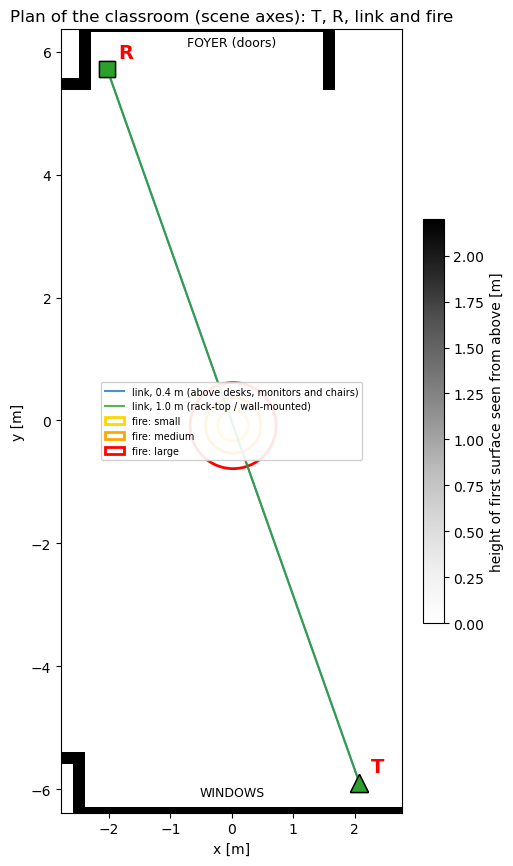

In [6]:
# bare-floor map: for every 5 cm cell, is the floor the first thing seen from the ceiling? (no desk, chair, rack)
_res = 0.05; GXc = np.arange(X0 + _res/2, X1, _res); GYc = np.arange(Y0 + _res/2, Y1, _res); _GX, _GY = np.meshgrid(GXc, GYc)
_o = np.c_[_GX.ravel(), _GY.ravel(), np.full(_GX.size, CEIL_Z - 0.05)]; _hit, _t, _n = cast(_o, [0, 0, -1])
_top = np.where(_hit, (CEIL_Z - 0.05 - _t), FLOOR_Z).reshape(_GX.shape)
_inside = ((_n[:, 2] < -0.3) & _hit).reshape(_GX.shape)      # the ray starts inside a solid (a wall pilaster, a column): the first surface it meets faces down
_top[_inside] = CEIL_Z                                       # treat those cells as full-height obstacles
from scipy import ndimage as ndi
BARE = _hit.reshape(_GX.shape) & (np.abs(_top - FLOOR_Z) < 0.05) & ~_inside
CLEAR = ndi.distance_transform_edt(np.pad(BARE, 1))[1:-1, 1:-1] * _res        # metres from each cell to the nearest furniture or wall

def clearance_at(xy):
    i = np.clip(((np.atleast_2d(xy)[:, 1] - GYc[0])/_res).round().astype(int), 0, len(GYc) - 1)
    j = np.clip(((np.atleast_2d(xy)[:, 0] - GXc[0])/_res).round().astype(int), 0, len(GXc) - 1)
    return CLEAR[i, j]

_BD = {}
def block_dist_at(height, xy):
    """Metres from xy to the nearest wall or to furniture tall enough to block a device at this height above the floor."""
    key = round(float(height), 2)
    if key not in _BD:
        blockers = _top > FLOOR_Z + height - 0.03
        _BD[key] = ndi.distance_transform_edt(~np.pad(blockers, 1, constant_values=True))[1:-1, 1:-1] * _res
    xy = np.atleast_2d(xy); i = np.clip(((xy[:, 1] - GYc[0])/_res).round().astype(int), 0, len(GYc) - 1); j = np.clip(((xy[:, 0] - GXc[0])/_res).round().astype(int), 0, len(GXc) - 1)
    return _BD[key][i, j]

def top_z_at(xy):
    """z of the first surface seen from the ceiling at xy (floor, desk top, rack top...)."""
    o = np.array([[xy[0], xy[1], CEIL_Z - 0.05]]); hit, t, _ = cast(o, [0, 0, -1])
    return float(CEIL_Z - 0.05 - t[0]) if hit[0] else FLOOR_Z

def nearest_bare(target, radius):
    ok = CLEAR >= radius; ii, jj = np.nonzero(ok)
    if len(ii) == 0: raise RuntimeError(f"no bare floor with {radius} m clearance; set the position by hand")
    pts = np.c_[GXc[jj], GYc[ii]]; k = np.argmin(np.linalg.norm(pts - target, axis=1)); return pts[k]

def object_near(p, tol=0.1):
    names = [name_of(o) for o in scene.objects.values()
             if np.all(np.array(o.mi_mesh.bbox().min) - tol <= p) and np.all(p <= np.array(o.mi_mesh.bbox().max) + tol)]
    return [n for n in names if n.lower() not in ("floor", "ceiling", "walls")]

# ---- the plan frame, from the foyer end ----
door_o = objs_named("foyer") + objs_named("door")
dc = (bbox_of(door_o)[0][:2] + bbox_of(door_o)[1][:2])/2 - CENTRE if door_o else np.array([0.0, 1.0])
DOWN = np.array([np.sign(dc[0]), 0.0]) if abs(dc[0]) > abs(dc[1]) else np.array([0.0, np.sign(dc[1])])     # toward the foyer
UP = -DOWN; RIGHT = np.array([UP[1], -UP[0]])                                                                # right as seen from above
LEN = (Y1 - Y0) if DOWN[1] != 0 else (X1 - X0); WID = (X1 - X0) if DOWN[1] != 0 else (Y1 - Y0)
TL = CENTRE + UP*LEN/2 - RIGHT*WID/2; BR = CENTRE + DOWN*LEN/2 + RIGHT*WID/2
T_MARK = TL + RIGHT*T_FROM_LEFT_M + DOWN*T_FROM_TOP_M
R_MARK = BR - RIGHT*R_FROM_RIGHT_M + UP*R_FROM_BOTTOM_M
print(f"foyer is toward {DOWN} (plan 'bottom'); T marked at x={T_MARK[0]:.2f}, y={T_MARK[1]:.2f}; R marked at x={R_MARK[0]:.2f}, y={R_MARK[1]:.2f}")

def los_blockers(T, R):
    """Distances to the first obstacle on the direct ray and on four rays 10 cm to each side / above / below (side rays ignore the first 0.6 m,
    where the device may sit on or beside a rack). Returns the first blocking point or None."""
    d = R - T; L = np.linalg.norm(d); u = d/L; side = np.cross(u, [0, 0, 1]); side /= np.linalg.norm(side)
    for k, off in enumerate(([0, 0, 0], *(side*s for s in (-0.12, 0.12)), [0, 0, -0.12], [0, 0, 0.12])):
        hit, t, _ = cast((T + off)[None], u[None])
        if hit[0] and t[0] < L - 0.05 and (k == 0 or t[0] > 0.6): return (float(t[0]), T + off + u*t[0]), L
    return None, L
los_check = los_blockers

DEVICE_CLEARANCE_M = 0.30
KEEP_EXACT_MARKED_POSITIONS = False   # True: never move T and R off the marked spots (a warning is printed if the link is then fragile)
def place_device(mark, height, over, other):
    """The marked spot at this height if it is at least DEVICE_CLEARANCE_M from every wall and every obstacle tall enough to block it
    (a device right beside a metal rack makes the link extremely sensitive to a few centimetres of movement); otherwise the nearest
    spot that is, from which the direct path to the other device is clear."""
    if over is not None: return np.array(over, float), "set by hand"
    d0 = float(block_dist_at(height, mark)[0])
    if d0 >= DEVICE_CLEARANCE_M or KEEP_EXACT_MARKED_POSITIONS:
        return np.array([mark[0], mark[1], FLOOR_Z + height]), f"at the marked spot ({d0:.2f} m from the nearest obstacle at that height)" + ("" if d0 >= DEVICE_CLEARANCE_M else "  WARNING: closer than the clearance, expect a fragile link")
    key = round(float(height), 2); ii, jj = np.nonzero(_BD[key] >= DEVICE_CLEARANCE_M); pts = np.c_[GXc[jj], GYc[ii]]
    far = np.array([other[0], other[1], FLOOR_Z + (other[2] - FLOOR_Z if len(other) == 3 else height)])
    for k in np.argsort(np.linalg.norm(pts - mark, axis=1))[:6000:5]:
        P = np.array([pts[k, 0], pts[k, 1], FLOOR_Z + height])
        if los_blockers(P, far)[0] is None: return P, f"MOVED {np.linalg.norm(pts[k] - mark):.2f} m (the marked spot is only {d0:.2f} m from an obstacle at this height; this is the nearest spot with {DEVICE_CLEARANCE_M} m clearance and a clear path)"
    p = pts[np.argmin(np.linalg.norm(pts - mark, axis=1))]
    return np.array([p[0], p[1], FLOOR_Z + height]), f"MOVED {np.linalg.norm(p - mark):.2f} m (no spot with a clear path found)"

SETUPS, NOTES = {}, {}
for name, h in LINK_SETUPS.items():
    T, nt = place_device(T_MARK, h, TX_POSITION, R_MARK)
    R, nr = place_device(R_MARK, h, RX_POSITION, T)
    SETUPS[name] = (T, R); NOTES[name] = (nt, nr)

SETUP_NAMES = list(SETUPS)
for name, (T, R) in SETUPS.items():
    blk, L = los_check(T, R)
    print(f"[{name}]\n   T=({T[0]:.2f}, {T[1]:.2f}, {T[2]:.2f}) {NOTES[name][0]}\n   R=({R[0]:.2f}, {R[1]:.2f}, {R[2]:.2f}) {NOTES[name][1]}\n   link length {L:.2f} m; direct path T to R: "
          + ("CLEAR of furniture" if blk is None else f"BLOCKED after {blk[0]:.1f} m near {object_near(blk[1]) or 'something'}"))

def fire_position_for(frac, setup):
    T, R = SETUPS[setup]; clear = STAGES["large"]["fire"][0] + 0.05
    p = nearest_bare(T[:2] + frac*(R[:2] - T[:2]), clear); d = (R - T)[:2]; off = abs(np.cross(d, p - T[:2]))/np.linalg.norm(d)
    return dict(x=float(p[0]), y=float(p[1]), zf=FLOOR_Z, ceiling=CEIL_Z - FLOOR_Z, frac=frac, off_los=float(off))

PRIMARY = SETUP_NAMES[PRIMARY_SETUP]; T0, R0 = SETUPS[PRIMARY]
FIRE_POS = {}
for name in SETUP_NAMES:
    for fr in sorted(set(LINK_SWEEP_FRACTIONS + [FIRE_ALONG_LINK])): FIRE_POS[(name, fr)] = fire_position_for(fr, name)
pos = dict(FIRE_POS[(PRIMARY, FIRE_ALONG_LINK)])
if FIRE_XY is not None: pos.update(x=float(FIRE_XY[0]), y=float(FIRE_XY[1]))
print(f"primary fire at x={pos['x']:.2f}, y={pos['y']:.2f} ({pos['off_los']:.2f} m from the direct T-R line); set-up for maps and CIR: {PRIMARY}")

# ---- figure: plan view ----
HM = np.where(_hit.reshape(_GX.shape), _top - FLOOR_Z, np.nan)
fig, ax = plt.subplots(figsize=(5.5, 10.5))
im = ax.imshow(HM, origin="lower", cmap="Greys", extent=[GXc[0], GXc[-1], GYc[0], GYc[-1]], vmin=0, vmax=2.2)
fig.colorbar(im, ax=ax, shrink=0.5, label="height of first surface seen from above [m]")
for o_ in scene.objects.values():
    n = name_of(o_)
    if n.lower().startswith(("rack", "lectern_desk")):
        lo_, hi_ = np.array(o_.mi_mesh.bbox().min), np.array(o_.mi_mesh.bbox().max); ax.text((lo_[0]+hi_[0])/2, (lo_[1]+hi_[1])/2, n.replace("_", " "), ha="center", va="center", fontsize=7, color="navy")
cols = ["tab:blue", "tab:green"]
for (name, (T, R)), c in zip(SETUPS.items(), cols):
    ax.plot([T[0], R[0]], [T[1], R[1]], "-", color=c, lw=1.5, alpha=0.8, label=f"link, {name}")
    ax.plot(T[0], T[1], "^", color=c, ms=13, mec="k"); ax.plot(R[0], R[1], "s", color=c, ms=11, mec="k")
ax.annotate("T", T0[:2], xytext=(8, 8), textcoords="offset points", fontsize=14, weight="bold", color="red")
ax.annotate("R", R0[:2], xytext=(8, 8), textcoords="offset points", fontsize=14, weight="bold", color="red")
for stg, c in zip(STAGES, ("gold", "orange", "red")):
    ax.add_patch(plt.Circle((pos["x"], pos["y"]), STAGES[stg]["fire"][0], fill=False, ec=c, lw=2, label=f"fire: {stg}"))
ax.annotate("FOYER (doors)", CENTRE + DOWN*(LEN/2 - 0.3), ha="center", fontsize=9, color="k"); ax.annotate("WINDOWS", CENTRE + UP*(LEN/2 - 0.3), ha="center", fontsize=9, color="k")
ax.set_aspect("equal"); ax.legend(loc="center", fontsize=7, framealpha=0.9); ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
ax.set_title("Plan of the classroom (scene axes): T, R, link and fire"); plt.show()

## 5b. See the simulated classroom and where the fire is

Ray-traced pictures of the same scene the detector uses (the ceiling is removed so the room is lit; fire = orange, smoke = grey).
1. **Looking from T toward the fire** at each growth stage.
2. **Top view in the orientation of your floor plan** (foyer at the bottom, T top-left, R bottom-right) with T, R, the link, the fire and the smoke footprint drawn on.

Set `RENDER_IMAGES = False` to skip them.

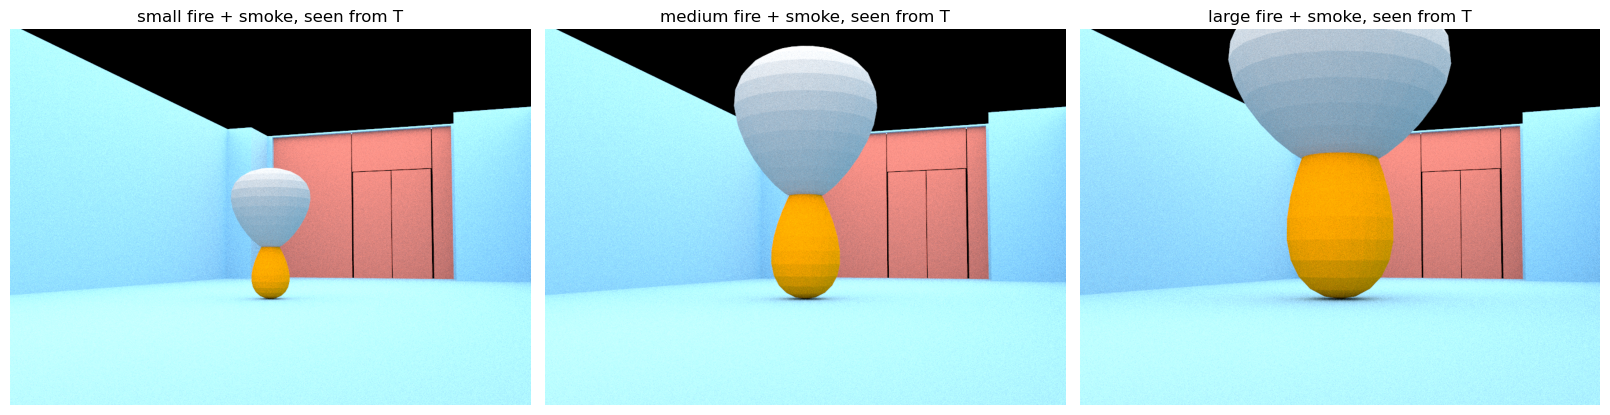

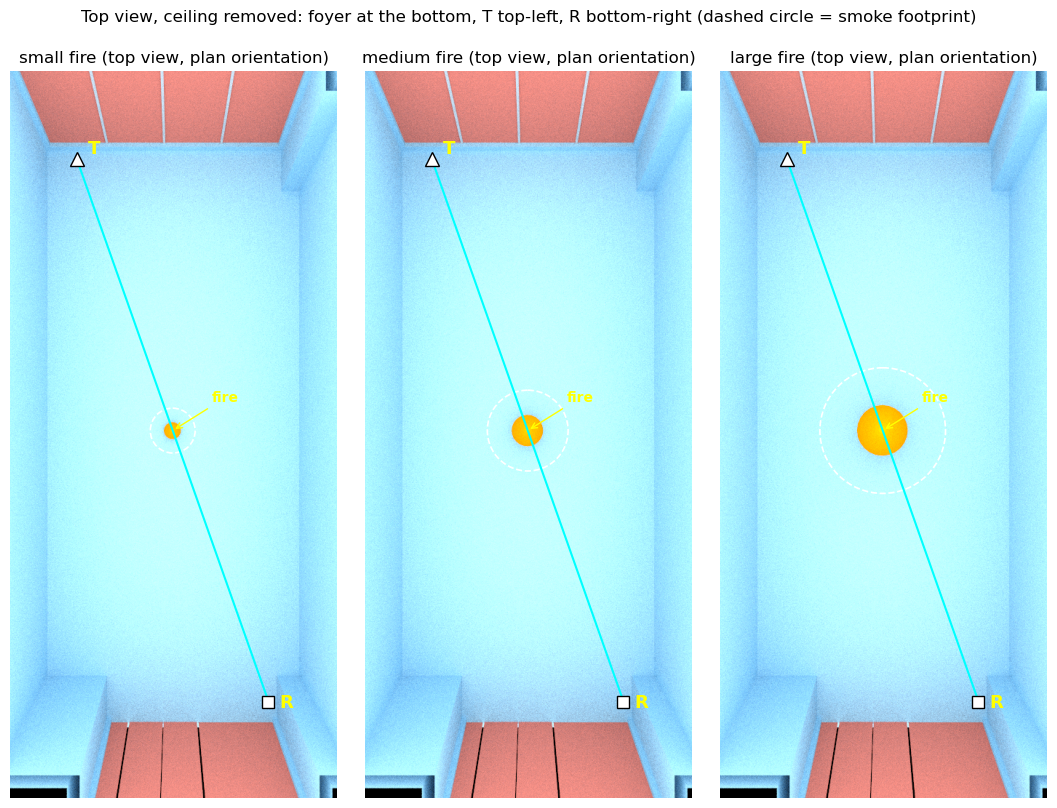

In [7]:
from sionna.rt import Camera
def to_img(bmp): return np.array(bmp.convert(mi.Bitmap.PixelFormat.RGB, mi.Struct.Type.UInt8, srgb_gamma=True))
CLIP_Z = CEIL_Z - 0.1

if RENDER_IMAGES:
    res_v = (640, 480) if QUICK_MODE else (900, 650)
    fig, axes = plt.subplots(1, len(STAGES), figsize=(5.4*len(STAGES), 4.4))
    for ax, stg in zip(np.atleast_1d(axes), STAGES):
        set_hazards("fire_smoke", stg, pos)
        cam = Camera(position=[float(v) for v in T0], look_at=[pos["x"], pos["y"], FLOOR_Z + 0.8])
        ax.imshow(to_img(scene.render(camera=cam, resolution=res_v, num_samples=RENDER_SAMPLES, lighting_scale=RENDER_LIGHT, clip_at=CLIP_Z, show_devices=False, return_bitmap=True)))
        ax.axis("off"); ax.set_title(f"{stg} fire + smoke, seen from T")
    plt.tight_layout(); plt.show()

    FOV = 40.0; Wpx, Hpx = (360, 800) if QUICK_MODE else (450, 1000)
    hcam = (WID*1.3/2)/np.tan(np.deg2rad(FOV/2)); f_px = (Wpx/2)/np.tan(np.deg2rad(FOV/2))
    cam_pos = np.array([CENTRE[0], CENTRE[1], FLOOR_Z + hcam]) - 0.005*np.array([UP[0], UP[1], 0.0])   # tiny shift makes the image's "up" = the plan's top
    def proj(p):
        q = np.asarray(p, float) - cam_pos; return Wpx/2 + f_px*(q[:2] @ RIGHT)/(-q[2]), Hpx/2 - f_px*(q[:2] @ UP)/(-q[2])
    fig, axes = plt.subplots(1, len(STAGES), figsize=(3.6*len(STAGES), 8.2))
    for ax, stg in zip(np.atleast_1d(axes), STAGES):
        set_hazards("fire", stg, pos)
        cam = Camera(position=cam_pos.tolist(), look_at=[float(CENTRE[0]), float(CENTRE[1]), FLOOR_Z])
        ax.imshow(to_img(scene.render(camera=cam, resolution=(Wpx, Hpx), num_samples=RENDER_SAMPLES, lighting_scale=RENDER_LIGHT, fov=FOV, clip_at=CLIP_Z, show_devices=False, return_bitmap=True)))
        (tx_, ty_), (rx_, ry_), (fx_, fy_) = proj(T0), proj(R0), proj([pos["x"], pos["y"], FLOOR_Z])
        ax.plot([tx_, rx_], [ty_, ry_], "-", color="cyan", lw=1.5); ax.plot(tx_, ty_, "^", color="white", ms=10, mec="k"); ax.plot(rx_, ry_, "s", color="white", ms=9, mec="k")
        ax.annotate("T", (tx_, ty_), xytext=(8, 4), textcoords="offset points", color="yellow", weight="bold", fontsize=13); ax.annotate("R", (rx_, ry_), xytext=(8, -4), textcoords="offset points", color="yellow", weight="bold", fontsize=13)
        ax.add_patch(plt.Circle((fx_, fy_), f_px*STAGES[stg]["smoke"][0]/hcam, fill=False, ls="--", ec="white", lw=1.2))
        ax.annotate("fire", (fx_, fy_), xytext=(fx_ + 0.12*Wpx, fy_ - 0.04*Hpx), color="yellow", weight="bold", arrowprops=dict(arrowstyle="->", color="yellow"))
        ax.set_xlim(0, Wpx); ax.set_ylim(Hpx, 0); ax.axis("off"); ax.set_title(f"{stg} fire (top view, plan orientation)")
    fig.suptitle("Top view, ceiling removed: foyer at the bottom, T top-left, R bottom-right (dashed circle = smoke footprint)"); plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()
    set_hazards("baseline", "small", pos)

## 6. The T to R link with and without fire

For each frequency and set-up:
1. **Baseline:** T and R at their positions, no fire.
2. **Normal fluctuation:** the same with T and R each nudged randomly by up to `CONTROL_JITTER_M` (positions within 10 cm of an obstacle are rejected). `N_CONTROLS` reruns give the largest change that happens without any fire.
3. **Fire:** for each fire position along the link, each growth stage, with fire only and with fire plus smoke.

Measured per run: **total received power** (all radio paths added up), **early-arrival power** (paths arriving within `EARLY_WINDOW_NS` of the direct path, which a wideband receiver cannot tell apart from it), **direct-path power** (the straight T to R path alone, an ideal quantity that needs a very wide receiver), **RMS delay spread**, and every path's delay and power (the channel impulse response).

**Detection rule:** each quantity gets a threshold = `CALIB_MARGIN` x the largest change seen in the no-fire reruns (never below 1 dB / 1 ns). The fire is **detected** if any quantity changes by at least its threshold. Because the thresholds come from the same reruns that define "normal", the false-alarm rate on those reruns is zero by construction; it is not an independent test.

In [8]:
def link_features(paths, T, R):
    a, tau = paths.cir(normalize_delays=False, out_type="numpy")
    aa = np.abs(a[0, 0, 0, 0, :, 0])**2; tt = tau[0, 0, :] if tau.ndim == 3 else tau[0, 0, 0, 0]
    keep = (tt >= 0) & (aa > 0); g, t = aa[keep], tt[keep]*1e9
    d_ns = np.linalg.norm(R - T)/0.299792458                                  # straight-line delay in ns
    out = dict(rx_dbm=-200.0, early_dbm=-200.0, rms_ds_ns=0.0, taps_ns=np.array([]), taps_dbm=np.array([]), los_dbm=-200.0, los_ns=d_ns)
    if len(g) == 0: return out
    p = TX_POWER_DBM + 10*np.log10(g); above = p > NOISE_FLOOR_DBM
    if not above.any(): return out
    out.update(taps_ns=t[above], taps_dbm=p[above], rx_dbm=TX_POWER_DBM + 10*np.log10(g[above].sum()))
    vis = above & (p > p.max() - TAP_DYNAMIC_RANGE_DB); gv, tv = g[vis], t[vis]; tm = (gv*tv).sum()/gv.sum()
    out["rms_ds_ns"] = float(np.sqrt((gv*(tv - tm)**2).sum()/gv.sum()))
    near = above & (np.abs(t - d_ns) < 1.5)
    if near.any(): out["los_dbm"] = float(p[near].max())
    early = above & (t >= d_ns - 1.5) & (t <= d_ns + EARLY_WINDOW_NS)
    if early.any(): out["early_dbm"] = float(TX_POWER_DBM + 10*np.log10(g[early].sum()))
    return out

def solve_link(freq, T, R):
    scene.frequency = freq; set_nodes([T], [R])
    return link_features(PathSolver()(scene, **PATH_KW), T, R)

def valid_jitter(P, k, tag, tries=80):
    """P nudged by up to CONTROL_JITTER_M; positions that would put the device inside furniture are rejected."""
    r = np.random.default_rng(SEED + 1000*k + tag)
    for _ in range(tries):
        q = P.copy(); q[:2] += r.uniform(-CONTROL_JITTER_M, CONTROL_JITTER_M, 2)
        if X0 + 0.1 < q[0] < X1 - 0.1 and Y0 + 0.1 < q[1] < Y1 - 0.1 and float(block_dist_at(q[2] - FLOOR_Z, q[:2])[0]) >= 0.10: return q
    return P.copy()

FL = lambda x: max(x, DBM_FLOOR)
def deltas(base, cur):
    return dict(total=FL(base["rx_dbm"]) - FL(cur["rx_dbm"]), early=FL(base["early_dbm"]) - FL(cur["early_dbm"]),
                direct=FL(base["los_dbm"]) - FL(cur["los_dbm"]), ds=cur["rms_ds_ns"] - base["rms_ds_ns"])

rows, CIR, CONTROL = [], {}, {}
t_start = time.time()
for sname, (T, R) in SETUPS.items():
    set_hazards("baseline", "small", pos)
    for fname, f in FREQUENCIES.items():
        base = solve_link(f, T, R)
        ctrl = [deltas(base, solve_link(f, valid_jitter(T, k, 0), valid_jitter(R, k, 1))) for k in range(1, N_CONTROLS + 1)]
        thr = {m: max(DS_FLOOR_NS if m == "ds" else DROP_FLOOR_DB, CALIB_MARGIN*max(abs(c[m]) for c in ctrl)) for m in ("total", "early", "direct", "ds")}
        CONTROL[(sname, fname)] = dict(ctrl={m: np.array([c[m] for c in ctrl]) for m in thr}, thr=thr, base=base)
        CIR[(sname, fname, "none", "none")] = base
        for fr in sorted(set(LINK_SWEEP_FRACTIONS + [FIRE_ALONG_LINK])):
            fp = pos if (sname == PRIMARY and fr == FIRE_ALONG_LINK) else FIRE_POS[(sname, fr)]
            for cond in CONDITIONS:
                for stg in STAGES:
                    set_hazards(cond, stg, fp); cur = solve_link(f, T, R); d = deltas(base, cur)
                    by = [m for m in ("early", "direct", "total", "ds") if (abs(d[m]) if m == "ds" else d[m]) >= thr[m]]
                    rows.append(dict(setup=sname, frequency=fname, fire_position=fr, fire_off_los_m=fp["off_los"], condition=cond, stage=stg,
                                     base_total_dbm=base["rx_dbm"], fire_total_dbm=cur["rx_dbm"], drop_total_db=d["total"], thr_total_db=thr["total"],
                                     base_early_dbm=base["early_dbm"], fire_early_dbm=cur["early_dbm"], drop_early_db=d["early"], thr_early_db=thr["early"],
                                     base_direct_dbm=base["los_dbm"], fire_direct_dbm=cur["los_dbm"], drop_direct_db=d["direct"], thr_direct_db=thr["direct"],
                                     base_ds_ns=base["rms_ds_ns"], fire_ds_ns=cur["rms_ds_ns"], d_ds_ns=d["ds"], thr_ds_ns=thr["ds"],
                                     detected=bool(by), detected_by=", ".join(by) if by else "-"))
                    if sname == PRIMARY and fr == FIRE_ALONG_LINK: CIR[(sname, fname, cond, stg)] = cur
            set_hazards("baseline", "small", pos)
    print(f"[{sname}] done, {time.time()-t_start:.0f}s elapsed")
RES = pd.DataFrame(rows); RES.to_csv(f"{RESULTS_DIR}/link_results.csv", index=False)
print(f"{len(RES)} link results saved. Largest no-fire change and the thresholds built from it:")
display(pd.DataFrame([dict(setup=k[0], frequency=k[1], **{f"{m}_largest_no_fire": float(np.abs(v['ctrl'][m]).max()) for m in v['thr']}, **{f"{m}_threshold": v['thr'][m] for m in v['thr']}) for k, v in CONTROL.items()]).round(2))

[0.4 m (above desks, monitors and chairs)] done, 17s elapsed
[1.0 m (rack-top / wall-mounted)] done, 34s elapsed
72 link results saved. Largest no-fire change and the thresholds built from it:


,setup,frequency,total_largest_no_fire,early_largest_no_fire,direct_largest_no_fire,ds_largest_no_fire,total_threshold,early_threshold,direct_threshold,ds_threshold
0,"0.4 m (above desks, monitors and chairs)",2.4 GHz,0.51,0.62,0.14,1.17,1.0,1.0,1.0,1.76
1,"0.4 m (above desks, monitors and chairs)",5G (3.55 GHz),0.33,0.38,0.14,0.65,1.0,1.0,1.0,1.00
2,1.0 m (rack-top / wall-mounted),2.4 GHz,0.54,0.67,0.14,1.23,1.0,1.0,1.0,1.84
3,1.0 m (rack-top / wall-mounted),5G (3.55 GHz),0.35,0.41,0.14,0.74,1.0,1.0,1.0,1.10


## 7. Signal distribution without fire

Received power over the room at the receiver's height, with T transmitting (primary set-up). The triangle is T, the square is R, and the line is the link.

2.4 GHz: maps done, 21s elapsed
5G (3.55 GHz): maps done, 42s elapsed
Map noise (standard deviation of the difference between two no-fire maps, after smoothing): {'2.4 GHz': 0.25, '5G (3.55 GHz)': 0.33} dB


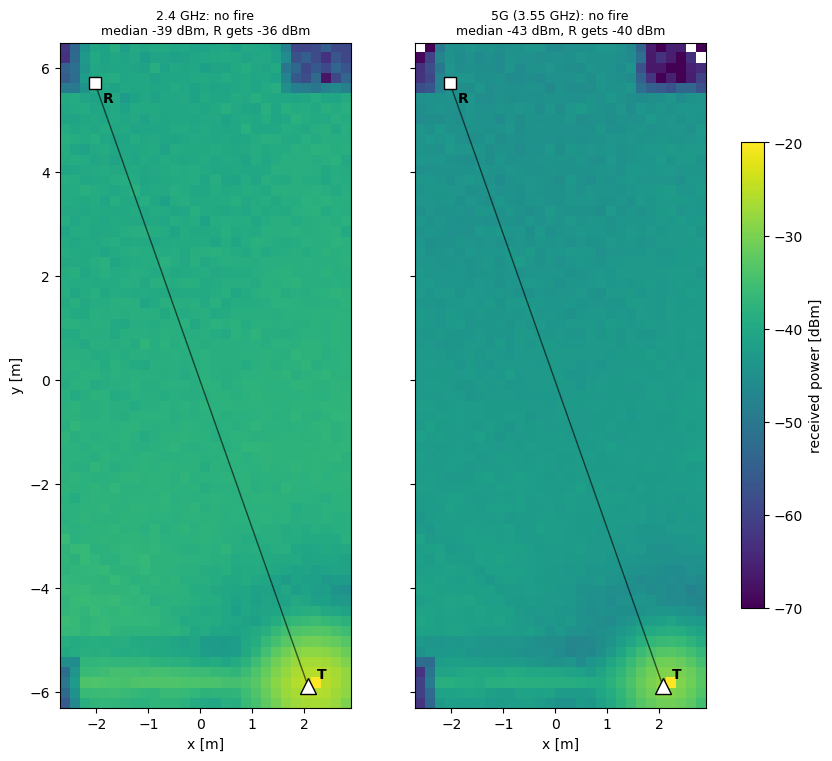

,frequency,median_rx_dbm,coverage_pct
0,2.4 GHz,-38.6,100.0
1,5G (3.55 GHz),-43.2,100.0


In [9]:
MAP_Z = float(FLOOR_Z + (MAP_HEIGHT_M if MAP_HEIGHT_M is not None else R0[2] - FLOOR_Z))
def radio_map(freq, seed=None):
    scene.frequency = freq; set_nodes([T0], [])
    kw = dict(RM_KW); kw["seed"] = SEED if seed is None else seed
    rm = RadioMapSolver()(scene, center=[float(CENTRE[0]), float(CENTRE[1]), float(MAP_Z)], orientation=[0.0, 0.0, 0.0],
                          size=[float(X1 - X0), float(Y1 - Y0)], cell_size=[float(CELL_M), float(CELL_M)], **kw)
    pg = rm.path_gain.numpy()[0]; return TX_POWER_DBM + 10*np.log10(np.maximum(pg, 1e-20)), rm.cell_centers.numpy()

MAPS = {}; EXTENT = None; t_start = time.time()
for fname, f in FREQUENCIES.items():
    set_hazards("baseline", "small", pos); MAPS[(fname, "none", "none")], cc = radio_map(f)
    MAPS[(fname, "none", "rerun")], _ = radio_map(f, seed=SEED + 7)          # the same empty room with other random rays: measures the map noise
    EXTENT = [float(cc[..., 0].min()), float(cc[..., 0].max()), float(cc[..., 1].min()), float(cc[..., 1].max())]
    for cond in CONDITIONS:
        for stg in STAGES: set_hazards(cond, stg, pos); MAPS[(fname, cond, stg)], _ = radio_map(f)
    set_hazards("baseline", "small", pos); print(f"{fname}: maps done, {time.time()-t_start:.0f}s elapsed")
np.savez_compressed(f"{RESULTS_DIR}/radio_maps_dbm.npz", **{"|".join(k): v for k, v in MAPS.items()})

from scipy import ndimage as ndi
def smooth_dbm(P):
    lin = np.where(P > -150, 10**(P/10), 0.0); n = ndi.uniform_filter((P > -150).astype(float), MAP_SMOOTH_CELLS)
    out = ndi.uniform_filter(lin, MAP_SMOOTH_CELLS)/np.maximum(n, 1e-9)
    return np.where(P > -150, 10*np.log10(np.maximum(out, 1e-20)), -200.0)
MAP_SIGMA = {}
for fname in FREQUENCIES:
    a, b = smooth_dbm(MAPS[(fname, "none", "none")]), smooth_dbm(MAPS[(fname, "none", "rerun")]); ok = (a > -150) & (b > -150)
    MAP_SIGMA[fname] = float(np.std(np.maximum(a, DBM_FLOOR)[ok] - np.maximum(b, DBM_FLOOR)[ok]))
print("Map noise (standard deviation of the difference between two no-fire maps, after smoothing):", {k: round(v, 2) for k, v in MAP_SIGMA.items()}, "dB")

def mark(ax, fire=True):
    ax.plot([T0[0], R0[0]], [T0[1], R0[1]], "-", color="k", lw=1, alpha=0.6)
    ax.plot(T0[0], T0[1], "^", color="white", ms=11, mec="k"); ax.plot(R0[0], R0[1], "s", color="white", ms=9, mec="k")
    ax.annotate("T", T0[:2], xytext=(6, 6), textcoords="offset points", weight="bold"); ax.annotate("R", R0[:2], xytext=(6, -14), textcoords="offset points", weight="bold")
    if fire: ax.plot(pos["x"], pos["y"], "o", mfc="none", mec="red", ms=10, mew=2)

fig, axes = plt.subplots(1, len(FREQUENCIES), figsize=(4.2*len(FREQUENCIES), 7.5), squeeze=False, sharey=True, constrained_layout=True)
cov_rows = []
for ax, fname in zip(axes[0], FREQUENCIES):
    P = MAPS[(fname, "none", "none")]; Pm = np.where(P > -150, P, np.nan)
    im = ax.imshow(Pm, origin="lower", extent=EXTENT, cmap="viridis", vmin=-70, vmax=-20); mark(ax, fire=False)
    ax.set_title(f"{fname}: no fire\nmedian {np.nanmedian(Pm):.0f} dBm, R gets {CIR[(PRIMARY, fname, 'none', 'none')]['rx_dbm']:.0f} dBm", fontsize=9); ax.set_xlabel("x [m]")
    cov_rows.append(dict(frequency=fname, median_rx_dbm=float(np.nanmedian(Pm)), coverage_pct=100*float((Pm[~np.isnan(Pm)] > NOISE_FLOOR_DBM + 10).mean())))
axes[0, 0].set_ylabel("y [m]"); fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.7, label="received power [dBm]"); plt.show()
pd.DataFrame(cov_rows).to_csv(f"{RESULTS_DIR}/baseline_coverage.csv", index=False); display(pd.DataFrame(cov_rows).round(1))

## 8. How the signal distribution changes with fire, and what R sees

Each map is **(with fire) minus (without fire)** in dB, after averaging neighbouring cells. **Blue = weaker, red = stronger; light grey = no change larger than the map noise.** The radio map is a Monte Carlo calculation, so even two maps of the empty room differ a little; the noise level is measured by rerunning the empty room with different random rays (printed above) and changes smaller than `MAP_NOISE_SIGMAS` times it are hidden. The box on each map gives the **result at the receiver R**: total power and early-arrival power without and with fire, and the verdict. The red circle is the fire; the black line is the link.

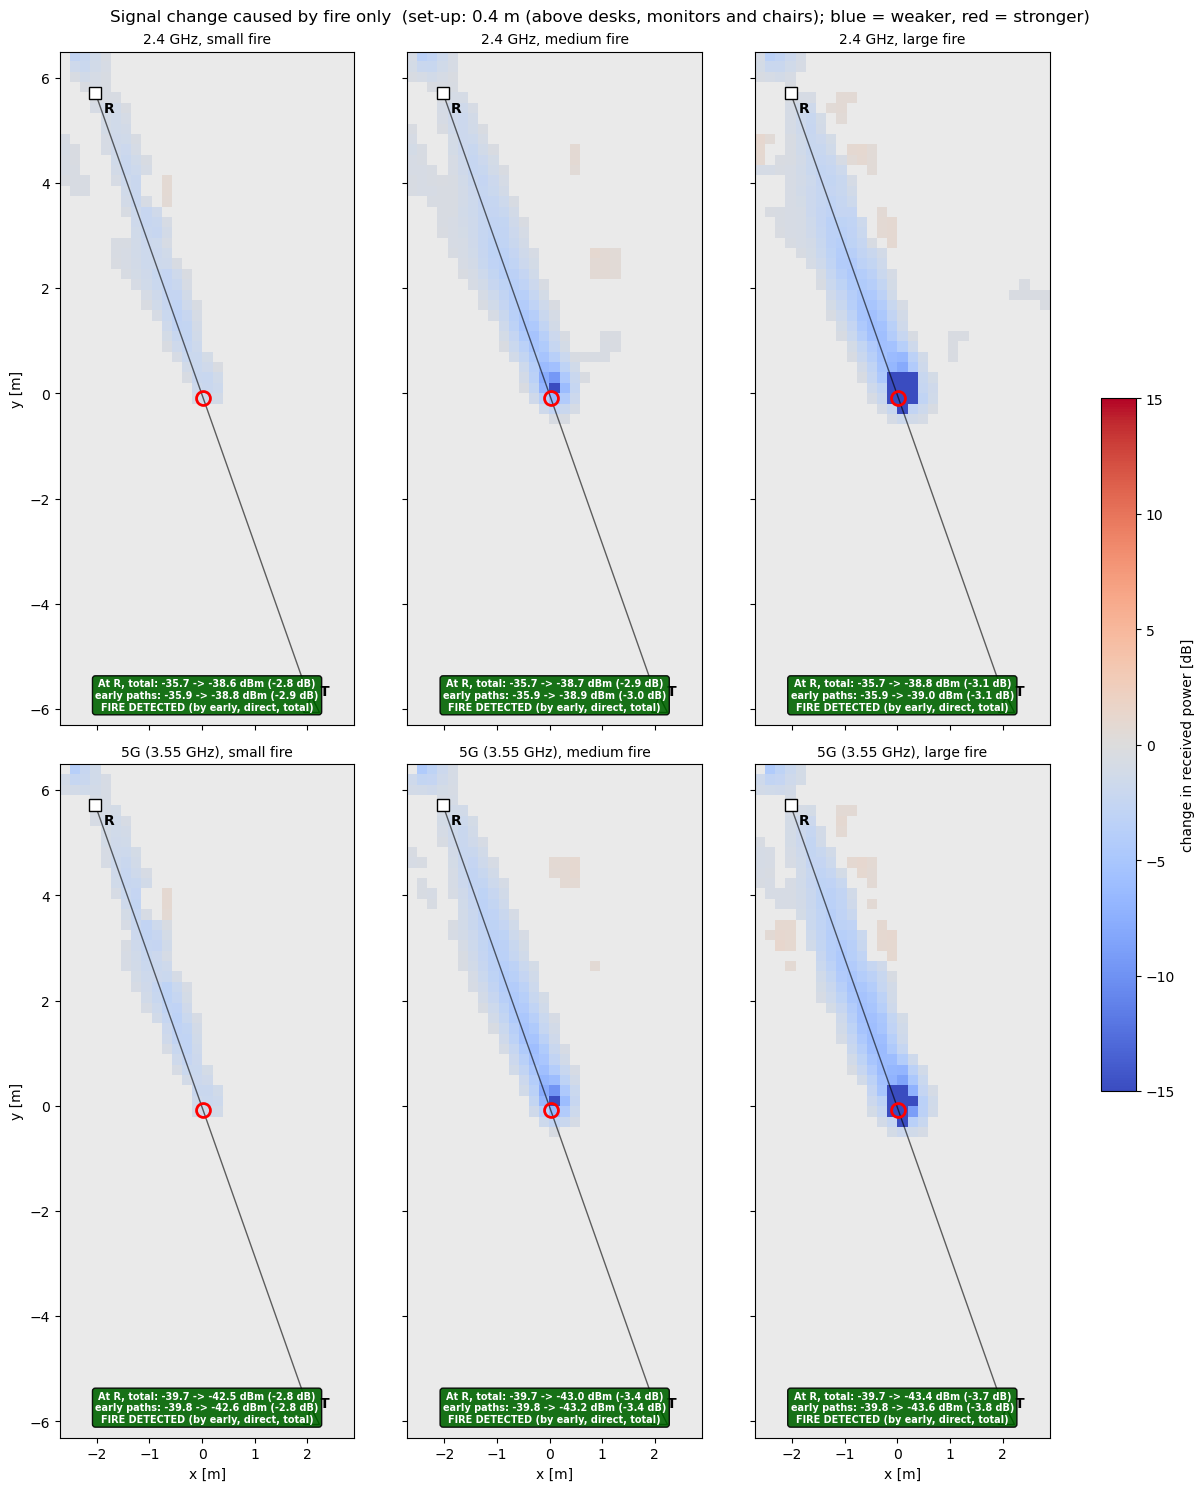

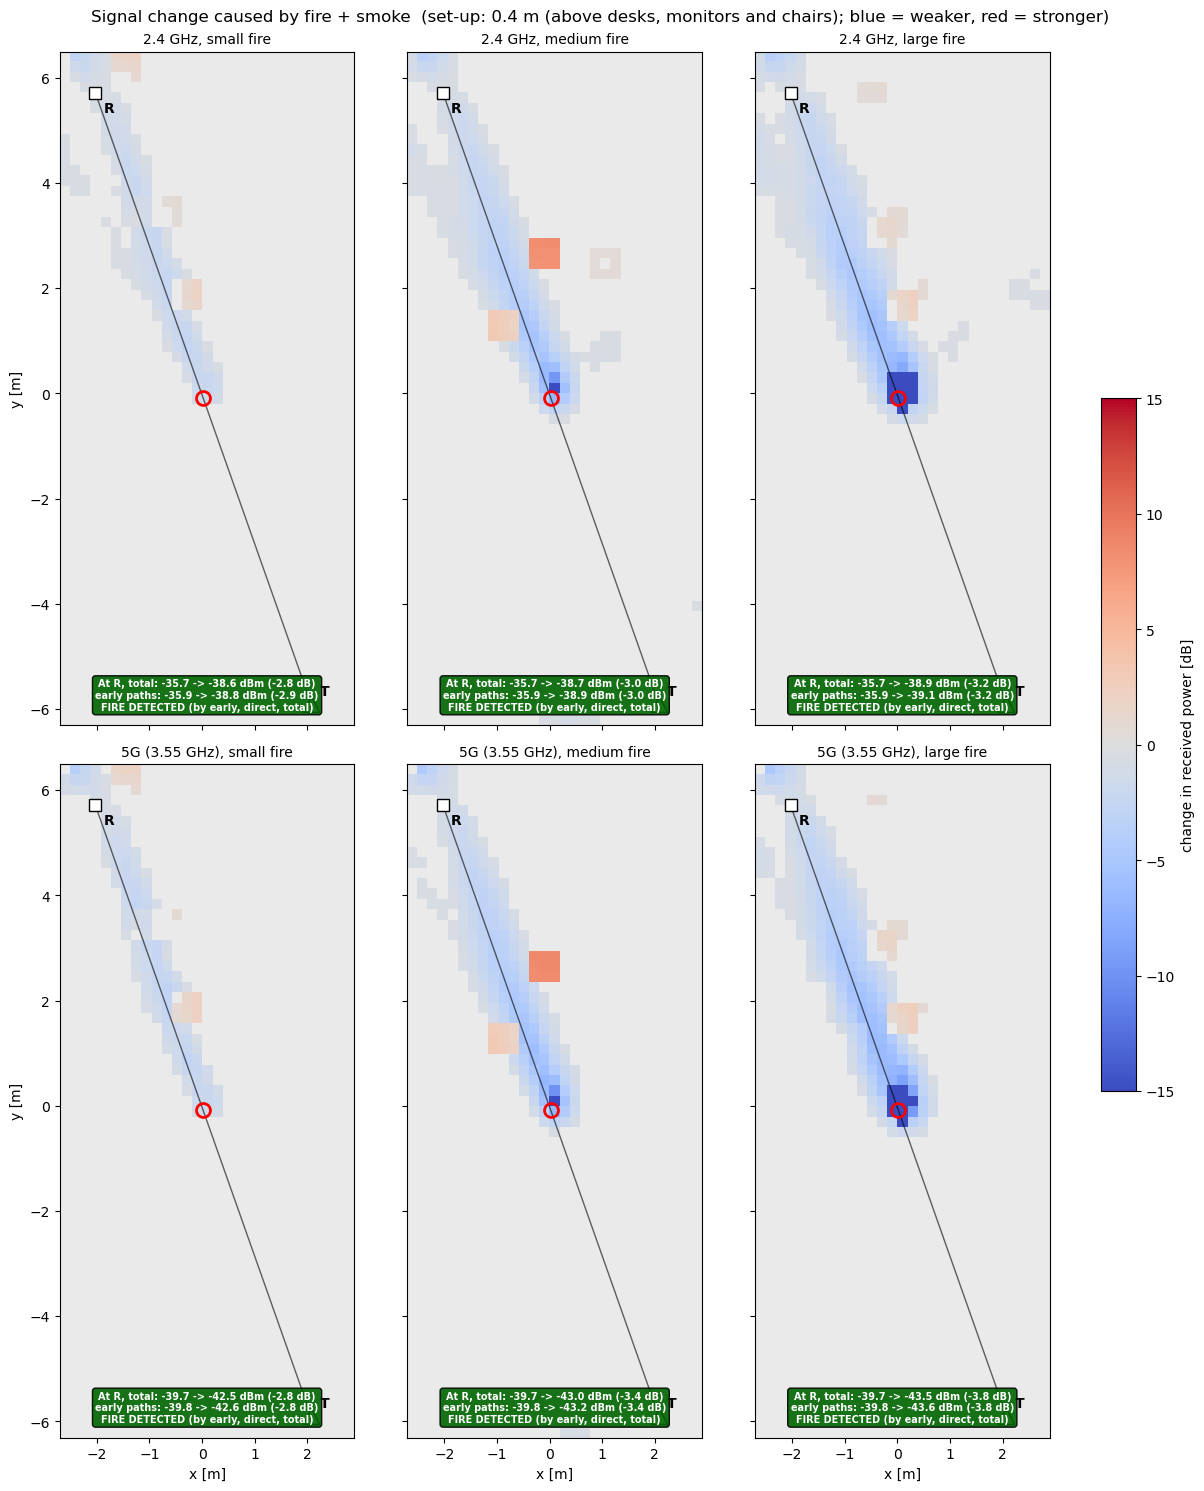

In [10]:
LABEL = {"fire": "fire only", "fire_smoke": "fire + smoke"}
DIFF_CMAP = plt.get_cmap("coolwarm").copy(); DIFF_CMAP.set_bad("0.92")
def diff_map(fname, cond, stg, hide_noise=True):
    b = smooth_dbm(MAPS[(fname, "none", "none")]); f_ = smooth_dbm(MAPS[(fname, cond, stg)])
    d = np.where(b > -150, np.maximum(f_, DBM_FLOOR) - np.maximum(b, DBM_FLOOR), np.nan)
    return np.where(np.abs(d) < MAP_NOISE_SIGMAS*MAP_SIGMA[fname], np.nan, d) if hide_noise else d

def verdict_row(setup, fname, cond, stg, fr=FIRE_ALONG_LINK):
    r = RES[(RES.setup == setup) & (RES.frequency == fname) & (RES.condition == cond) & (RES.stage == stg) & (RES.fire_position == fr)]
    return r.iloc[0]

for cond in CONDITIONS:
    fig, axes = plt.subplots(len(FREQUENCIES), len(STAGES), figsize=(4.0*len(STAGES), 7.4*len(FREQUENCIES)), squeeze=False, sharex=True, sharey=True, constrained_layout=True)
    for r_, fname in enumerate(FREQUENCIES):
        for c_, stg in enumerate(STAGES):
            ax = axes[r_, c_]; im = ax.imshow(diff_map(fname, cond, stg), origin="lower", extent=EXTENT, cmap=DIFF_CMAP, vmin=-DIFF_RANGE_DB, vmax=DIFF_RANGE_DB); mark(ax)
            v = verdict_row(PRIMARY, fname, cond, stg); det = bool(v.detected)
            ax.text(0.5, 0.02, f"At R, total: {v.base_total_dbm:.1f} -> {v.fire_total_dbm:.1f} dBm ({-v.drop_total_db:+.1f} dB)\nearly paths: {v.base_early_dbm:.1f} -> {v.fire_early_dbm:.1f} dBm ({-v.drop_early_db:+.1f} dB)\n"
                    + (f"FIRE DETECTED (by {v.detected_by})" if det else "not detected"),
                    transform=ax.transAxes, ha="center", va="bottom", fontsize=7, weight="bold", color="white", bbox=dict(boxstyle="round", fc="darkgreen" if det else "dimgray", alpha=0.9))
            ax.set_title(f"{fname}, {stg} fire", fontsize=10)
            if r_ == len(FREQUENCIES) - 1: ax.set_xlabel("x [m]")
            if c_ == 0: ax.set_ylabel("y [m]")
    fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.5, label="change in received power [dB]")
    fig.suptitle(f"Signal change caused by {LABEL[cond]}  (set-up: {PRIMARY}; blue = weaker, red = stronger)"); plt.show()

## 9. Evidence that the fire is detected

**Figure A: change at R compared with normal fluctuation.** Grey dots are the no-fire reruns (T and R nudged); bars are the power drop caused by fire. The dashed line is that quantity's detection threshold. A bar above the line is a detection by that quantity. The first row is the **early-arrival power** (what a wideband receiver measures), the second the **total power**.

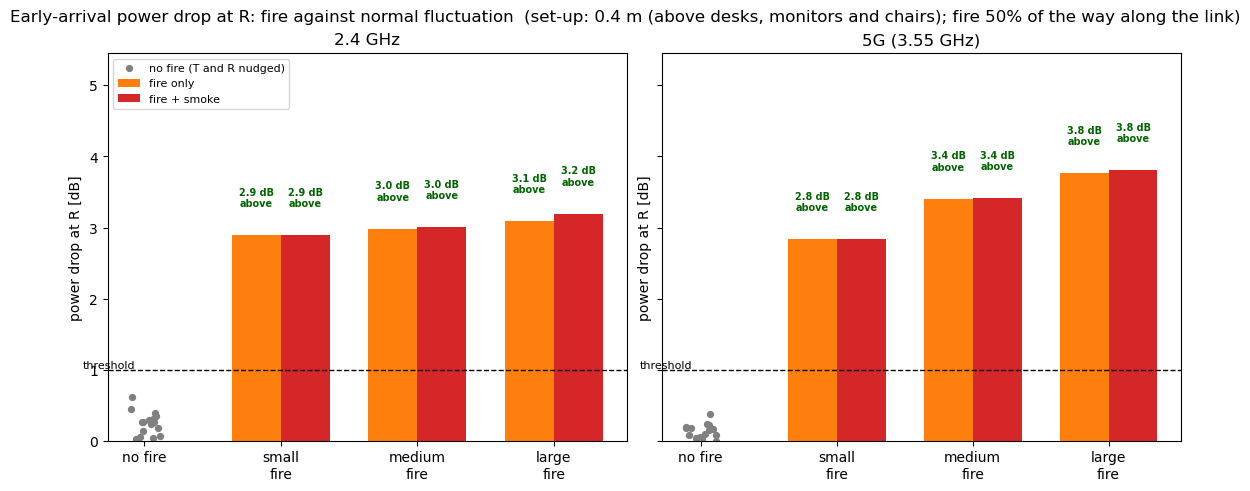

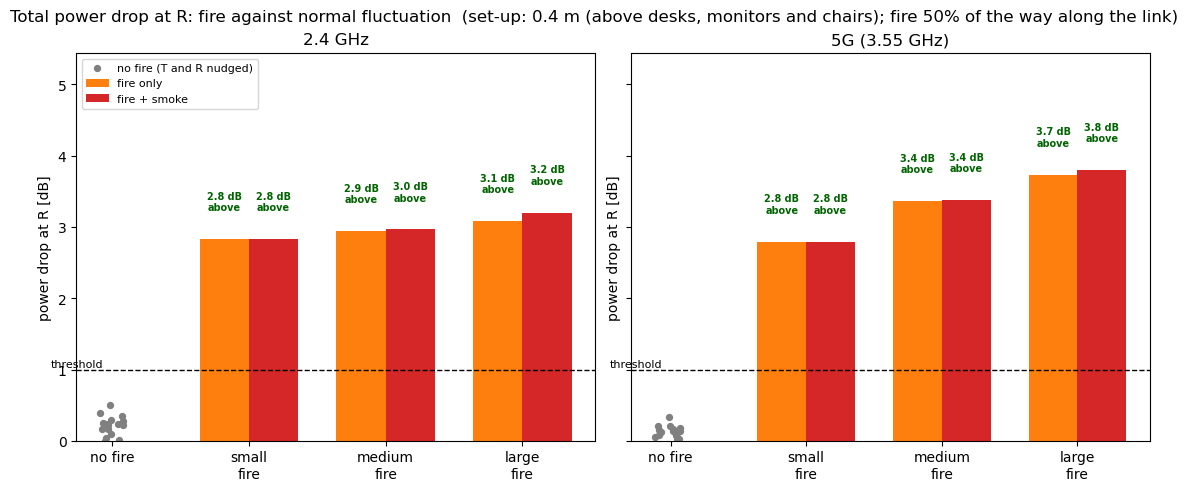

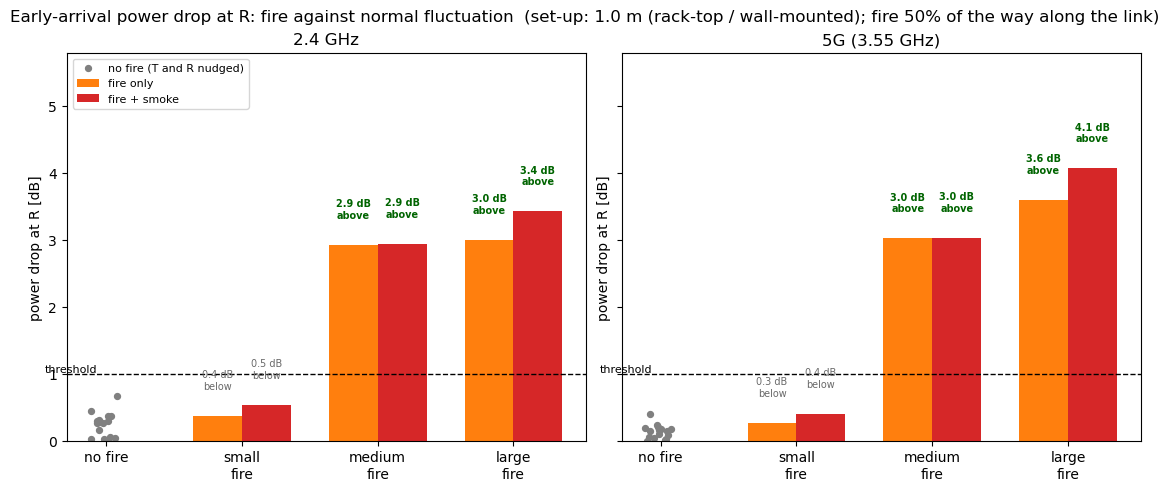

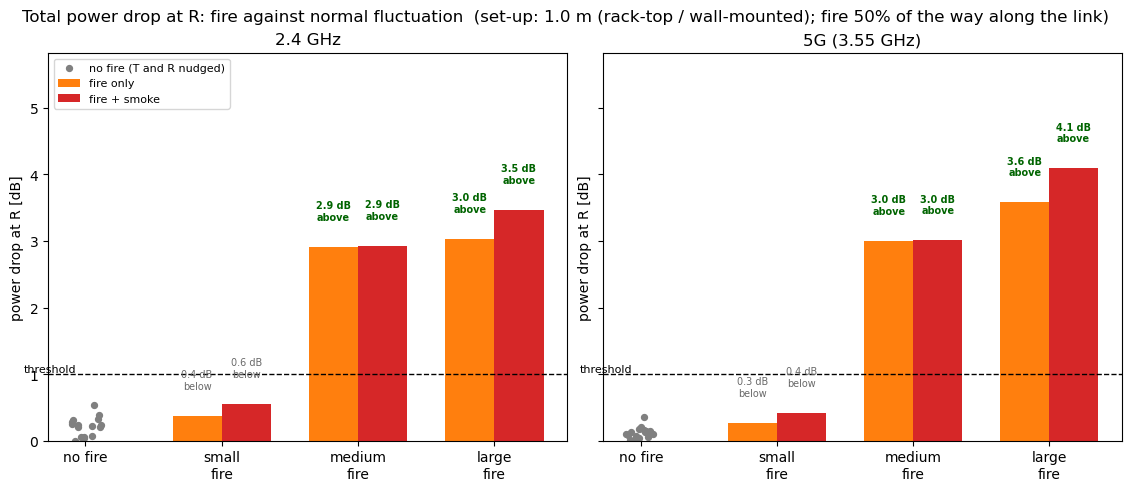

In [11]:
def evidence_bars(setup, metric, title):
    fig, axes = plt.subplots(1, len(FREQUENCIES), figsize=(5.6*len(FREQUENCIES), 4.8), squeeze=False, sharey=True, constrained_layout=True)
    for ax, fname in zip(axes[0], FREQUENCIES):
        C = CONTROL[(setup, fname)]; xs = np.arange(len(STAGES)) + 1; w = 0.36; thr = C["thr"][metric]
        ax.scatter(rng.uniform(-0.12, 0.12, len(C["ctrl"][metric])), np.abs(C["ctrl"][metric]), color="gray", s=18, label="no fire (T and R nudged)")
        for k, (cond, col) in enumerate(zip(CONDITIONS, ("tab:orange", "tab:red"))):
            vals = [verdict_row(setup, fname, cond, s) for s in STAGES]; dv = [getattr(v, f"drop_{metric}_db") for v in vals]
            bars = ax.bar(xs + (k - 0.5)*w, [max(x, 0) for x in dv], w, color=col, label=LABEL[cond])
            for b_, x in zip(bars, dv):
                ax.text(b_.get_x() + w/2, b_.get_height() + 0.4, f"{x:.1f} dB\n" + ("above" if x >= thr else "below"), ha="center", fontsize=7, weight="bold" if x >= thr else None, color="darkgreen" if x >= thr else "dimgray")
        ax.axhline(thr, color="k", ls="--", lw=1); ax.text(-0.45, thr, "threshold", va="bottom", ha="left", fontsize=8)
        ax.set_ylim(0, max(np.abs(C["ctrl"][metric]).max(), thr, max(getattr(verdict_row(setup, fname, c_, s_), f"drop_{metric}_db") for c_ in CONDITIONS for s_ in STAGES))*1.3 + 0.5)
        ax.set_xticks([0] + list(xs)); ax.set_xticklabels(["no fire"] + [f"{s}\nfire" for s in STAGES]); ax.set_title(fname); ax.set_ylabel("power drop at R [dB]")
    axes[0, 0].legend(fontsize=8, loc="upper left"); fig.suptitle(f"{title}  (set-up: {setup}; fire {FIRE_ALONG_LINK:.0%} of the way along the link)"); plt.show()

for sname in SETUP_NAMES:
    evidence_bars(sname, "early", "Early-arrival power drop at R: fire against normal fluctuation")
    evidence_bars(sname, "total", "Total power drop at R: fire against normal fluctuation")

**Figure B: the channel impulse response (CIR).** Each stem is one radio path: its position is how long the signal takes (1 ns is about 0.3 m of path) and its height is its power. Blue is without fire and red with fire. The dashed line is where the straight T to R path arrives. If the fire sits on the direct path, that stem shrinks or disappears; the boxes give the numbers.

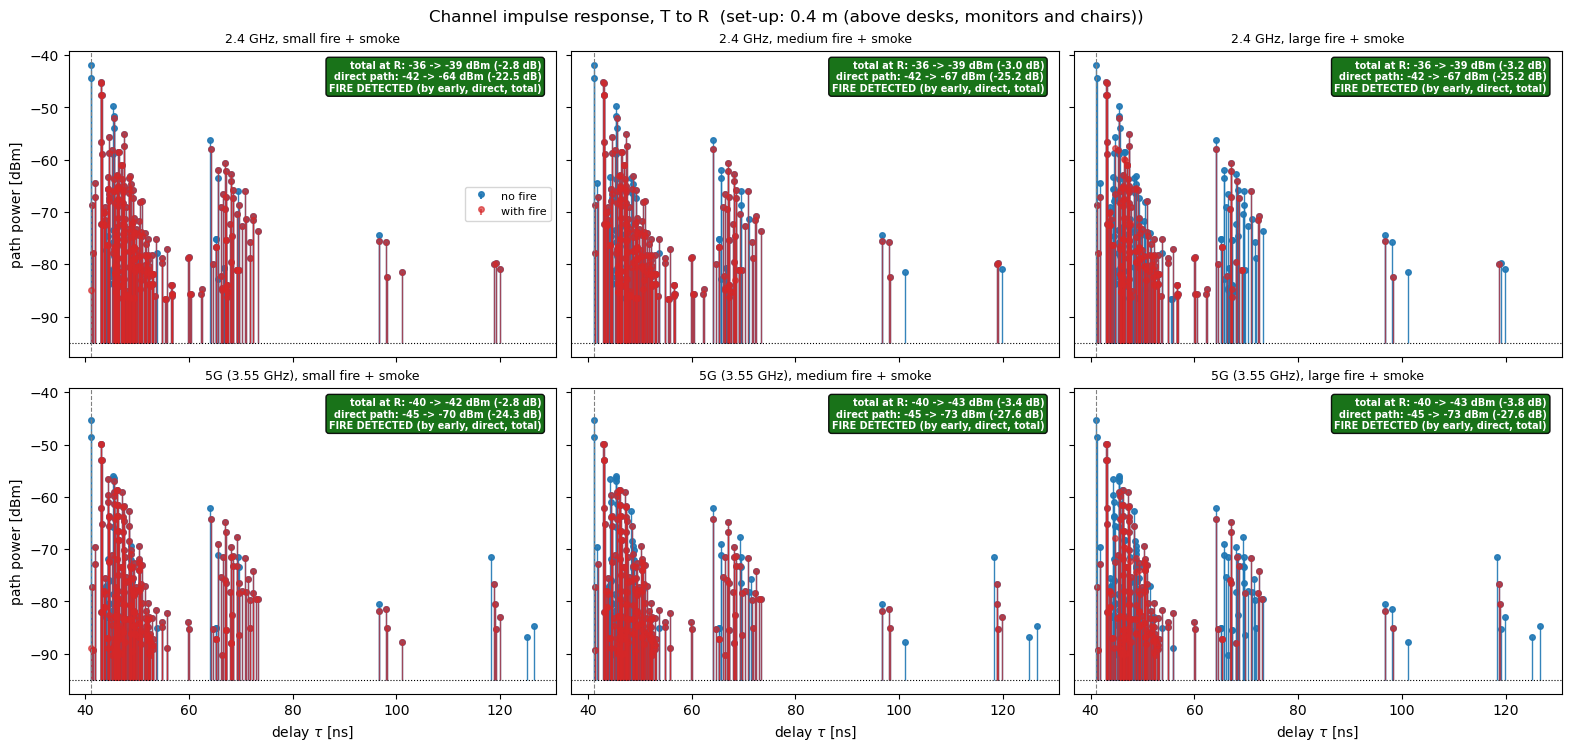

In [12]:
CIR_COND = "fire_smoke"
fig, axes = plt.subplots(len(FREQUENCIES), len(STAGES), figsize=(5.2*len(STAGES), 3.7*len(FREQUENCIES)), squeeze=False, sharex=True, sharey=True, constrained_layout=True)
for r_, fname in enumerate(FREQUENCIES):
    for c_, stg in enumerate(STAGES):
        ax = axes[r_, c_]; b = CIR[(PRIMARY, fname, "none", "none")]; cur = CIR[(PRIMARY, fname, CIR_COND, stg)]
        top = max([d["taps_dbm"].max() for d in (b, cur) if len(d["taps_dbm"])] or [NOISE_FLOOR_DBM])
        for d, lab, col, al in ((b, "no fire", "tab:blue", 0.9), (cur, "with fire", "tab:red", 0.65)):
            k = d["taps_dbm"] > max(NOISE_FLOOR_DBM, top - 45)
            if k.any():
                ml, sl, _ = ax.stem(d["taps_ns"][k], d["taps_dbm"][k], bottom=NOISE_FLOOR_DBM, linefmt=col, markerfmt="o", basefmt=" ", label=lab)
                plt.setp(ml, markersize=4, alpha=al, color=col); plt.setp(sl, linewidth=1, alpha=al, color=col)
        ax.axhline(NOISE_FLOOR_DBM, color="k", ls=":", lw=0.8); ax.axvline(b["los_ns"], color="gray", ls="--", lw=0.8)
        v = verdict_row(PRIMARY, fname, CIR_COND, stg)
        txt = f"total at R: {v.base_total_dbm:.0f} -> {v.fire_total_dbm:.0f} dBm ({-v.drop_total_db:+.1f} dB)\ndirect path: {v.base_direct_dbm:.0f} -> {v.fire_direct_dbm:.0f} dBm ({-v.drop_direct_db:+.1f} dB)\n" + (f"FIRE DETECTED (by {v.detected_by})" if v.detected else "not detected")
        ax.text(0.97, 0.97, txt, transform=ax.transAxes, ha="right", va="top", fontsize=7, weight="bold", color="white", bbox=dict(boxstyle="round", fc="darkgreen" if v.detected else "dimgray", alpha=0.9))
        ax.set_title(f"{fname}, {stg} fire + smoke", fontsize=9)
        if r_ == len(FREQUENCIES) - 1: ax.set_xlabel(r"delay $\tau$ [ns]")
        if c_ == 0: ax.set_ylabel("path power [dBm]")
axes[0, 0].legend(loc="center right", fontsize=8); fig.suptitle(f"Channel impulse response, T to R  (set-up: {PRIMARY})"); plt.show()

**Figure C: does it still work if the fire is elsewhere?** The same link with the fire at three places along the line from T to R (each snapped to the nearest bare floor, so near the desks it can end up beside the link: the row label gives how far). Each cell shows the early-arrival power drop at R and whether anything counted as a detection.

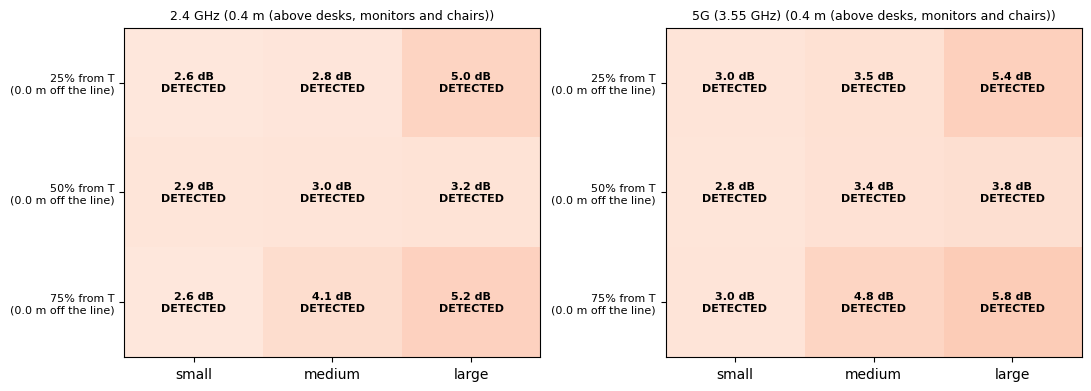

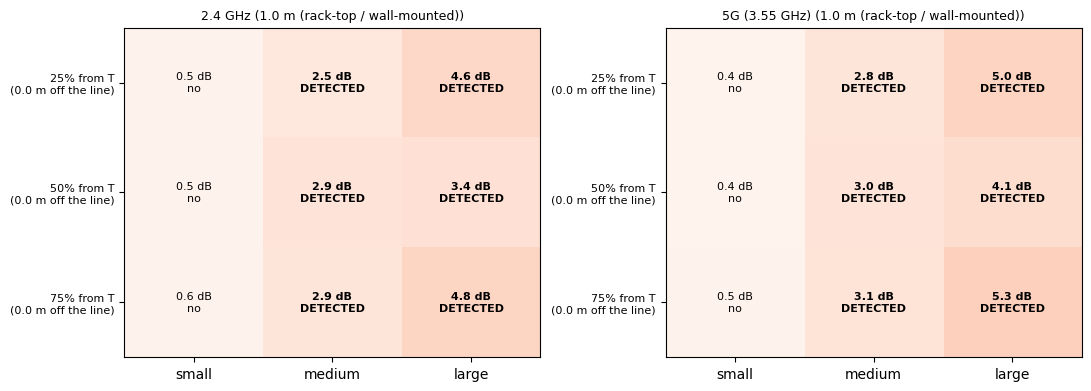

In [13]:
for sname in SETUP_NAMES:
    fig, axes = plt.subplots(1, len(FREQUENCIES), figsize=(5.4*len(FREQUENCIES), 3.8), squeeze=False, constrained_layout=True)
    for ax, fname in zip(axes[0], FREQUENCIES):
        sub = RES[(RES.setup == sname) & (RES.frequency == fname) & (RES.condition == "fire_smoke")]
        fr_list = sorted(sub.fire_position.unique()); g_ = lambda fr, s, col: sub[(sub.fire_position == fr) & (sub.stage == s)][col].iloc[0]
        M = np.array([[g_(fr, s, "drop_early_db") for s in STAGES] for fr in fr_list]); Dt = np.array([[bool(g_(fr, s, "detected")) for s in STAGES] for fr in fr_list])
        ax.imshow(np.clip(M, 0, 30), cmap="Reds", vmin=0, vmax=30, aspect="auto")
        for i in range(M.shape[0]):
            for j in range(M.shape[1]): ax.text(j, i, f"{M[i, j]:.1f} dB\n{'DETECTED' if Dt[i, j] else 'no'}", ha="center", va="center", fontsize=8, weight="bold" if Dt[i, j] else None)
        ax.set_xticks(range(len(STAGES))); ax.set_xticklabels(list(STAGES)); ax.set_yticks(range(len(fr_list)))
        ax.set_yticklabels([f"{fr:.0%} from T\n({g_(fr, 'small', 'fire_off_los_m'):.1f} m off the line)" for fr in fr_list], fontsize=8); ax.set_title(f"{fname} ({sname})", fontsize=9)
    plt.show()

## 10. Results table and what it says

The table is for the primary fire position (halfway along the link). Each `drop_*_db` is the power drop at R and each `thr_*_db` is its threshold from the no-fire reruns; `detected_by` lists the quantities that crossed their thresholds. Every position is in `results/link_results.csv`.

In [14]:
SHOW = ["setup", "frequency", "condition", "stage", "drop_early_db", "thr_early_db", "drop_direct_db", "thr_direct_db", "drop_total_db", "thr_total_db", "d_ds_ns", "thr_ds_ns", "detected", "detected_by"]
summary = RES[RES.fire_position == FIRE_ALONG_LINK][SHOW]; summary.to_csv(f"{RESULTS_DIR}/summary_primary_fire_position.csv", index=False)
display(summary.round(2))

def sentence(r):
    stage = f"{r.stage} fire" + (" with smoke" if r.condition == "fire_smoke" else "")
    nums = f"early-arrival power {-r.drop_early_db:+.1f} dB (threshold {r.thr_early_db:.1f}), direct path {-r.drop_direct_db:+.1f} dB (threshold {r.thr_direct_db:.1f}), total power {-r.drop_total_db:+.1f} dB (threshold {r.thr_total_db:.1f})"
    return (f"DETECTED (by {r.detected_by}): " if r.detected else "not detected: ") + f"{stage}, {r.frequency}, {r.setup}: {nums}."
print("What the simulation shows (fire halfway along the link):\n")
for _, r in summary.iterrows(): print(" -", sentence(r))
json.dump(dict(SEED=SEED, FREQUENCIES=FREQUENCIES, setups={k: [v[0].tolist(), v[1].tolist()] for k, v in SETUPS.items()}, primary_fire=pos, TX_POWER_DBM=TX_POWER_DBM,
               NOISE_FLOOR_DBM=float(NOISE_FLOOR_DBM), N_CONTROLS=N_CONTROLS, CONTROL_JITTER_M=CONTROL_JITTER_M, CALIB_MARGIN=CALIB_MARGIN, EARLY_WINDOW_NS=EARLY_WINDOW_NS,
               FIRE=FIRE, SMOKE=SMOKE, STAGES=STAGES, PATH_KW=PATH_KW, sionna_rt=sionna.rt.__version__), open(f"{RESULTS_DIR}/run_config.json", "w"), indent=2)

,setup,frequency,condition,stage,drop_early_db,thr_early_db,drop_direct_db,thr_direct_db,drop_total_db,thr_total_db,d_ds_ns,thr_ds_ns,detected,detected_by
6,"0.4 m (above desks, monitors and chairs)",2.4 GHz,fire,small,2.89,1.0,22.52,1.0,2.83,1.0,0.51,1.76,True,"early, direct, total"
7,"0.4 m (above desks, monitors and chairs)",2.4 GHz,fire,medium,2.98,1.0,25.19,1.0,2.94,1.0,0.28,1.76,True,"early, direct, total"
8,"0.4 m (above desks, monitors and chairs)",2.4 GHz,fire,large,3.09,1.0,25.19,1.0,3.08,1.0,-0.08,1.76,True,"early, direct, total"
9,"0.4 m (above desks, monitors and chairs)",2.4 GHz,fire_smoke,small,2.89,1.0,22.52,1.0,2.83,1.0,0.51,1.76,True,"early, direct, total"
10,"0.4 m (above desks, monitors and chairs)",2.4 GHz,fire_smoke,medium,3.01,1.0,25.19,1.0,2.97,1.0,0.29,1.76,True,"early, direct, total"
11,"0.4 m (above desks, monitors and chairs)",2.4 GHz,fire_smoke,large,3.19,1.0,25.19,1.0,3.20,1.0,-0.14,1.76,True,"early, direct, total"
24,"0.4 m (above desks, monitors and chairs)",5G (3.55 GHz),fire,small,2.84,1.0,24.32,1.0,2.79,1.0,0.68,1.00,True,"early, direct, total"
25,"0.4 m (above desks, monitors and chairs)",5G (3.55 GHz),fire,medium,3.40,1.0,27.63,1.0,3.36,1.0,0.58,1.00,True,"early, direct, total"
26,"0.4 m (above desks, monitors and chairs)",5G (3.55 GHz),fire,large,3.77,1.0,27.63,1.0,3.74,1.0,0.49,1.00,True,"early, direct, total"
27,"0.4 m (above desks, monitors and chairs)",5G (3.55 GHz),fire_smoke,small,2.84,1.0,24.32,1.0,2.79,1.0,0.68,1.00,True,"early, direct, total"


What the simulation shows (fire halfway along the link):

 - DETECTED (by early, direct, total): small fire, 2.4 GHz, 0.4 m (above desks, monitors and chairs): early-arrival power -2.9 dB (threshold 1.0), direct path -22.5 dB (threshold 1.0), total power -2.8 dB (threshold 1.0).
 - DETECTED (by early, direct, total): medium fire, 2.4 GHz, 0.4 m (above desks, monitors and chairs): early-arrival power -3.0 dB (threshold 1.0), direct path -25.2 dB (threshold 1.0), total power -2.9 dB (threshold 1.0).
 - DETECTED (by early, direct, total): large fire, 2.4 GHz, 0.4 m (above desks, monitors and chairs): early-arrival power -3.1 dB (threshold 1.0), direct path -25.2 dB (threshold 1.0), total power -3.1 dB (threshold 1.0).
 - DETECTED (by early, direct, total): small fire with smoke, 2.4 GHz, 0.4 m (above desks, monitors and chairs): early-arrival power -2.9 dB (threshold 1.0), direct path -22.5 dB (threshold 1.0), total power -2.8 dB (threshold 1.0).
 - DETECTED (by early, direct, total): med

## 11. How to read this, and its limits

- **What "detected through the wireless signal" means here:** the T to R link behaves differently with the fire present than it ever does without it. The evidence is the power drop at R (figure A and the map boxes), the lost or weakened direct path and the new longer paths (figure B), and the result at several fire positions (figure C).
- **Early-arrival power is the useful quantity.** The total received power is dominated by reflections that arrive within a few nanoseconds of the direct path, so a fire on the direct path changes the total only a little. The direct path alone, and the early arrivals, change much more. Seeing them needs a receiver that resolves about `EARLY_WINDOW_NS`, roughly 100 MHz. A 20 MHz Wi-Fi channel cannot, and 2.4 GHz Wi-Fi channels are at most 40 MHz wide; this simulation assumes ideal resolution for both frequencies.
- **It detects change, not fire.** A person, a trolley or an opened door that blocks the link would trigger it too, and the simulation does not model heat, CO2 or smoke chemistry.
- **The flame must reach the link.** A flame shorter than the link height does not block the direct path, so the result depends on the set-up height, which is not on your plan.
- **Smoke barely absorbs radio waves** with the assumed values (conductivity 1e-4 S/m), so "fire + smoke" is close to "fire only". The smoke values are a team assumption with no measurement behind them.
- **Fire values:** conductivity 0.05 S/m comes from one X-band measurement of a vegetation fire. Try 0.02 and 0.09 (`FIRE["conductivity"]`) to see how much the verdicts depend on it.
- **Constant material values:** fire and smoke do not change with frequency here, so a difference between 2.4 GHz and 5G mostly reflects how the room propagates.
- **Thin-slab model:** Sionna treats fire and smoke as slabs of fixed thickness, not volumes with loss per metre.
- **Deterministic ray tracing, no receiver noise.** "Normal fluctuation" is modelled by nudging T and R by up to 15 cm, which is not the same as real measurement noise, and the thresholds are calibrated on those same reruns. Radio maps carry some Monte Carlo noise, so treat map changes under 1 to 2 dB with caution.
- **Placement:** T and R are positioned from a hand-drawn arrow on your plan, measured off the picture.

**Outputs** are in `results/`: `link_results.csv` (every case), `summary_primary_fire_position.csv`, `baseline_coverage.csv`, `radio_maps_dbm.npz`, `run_config.json`.

## 12. Fire-behaviour classifier: telling a growing fire from an empty room and from people

Sections 1 to 11 use **one link and a threshold**. Anything that blocks the direct path by enough (a person, for instance) triggers that rule, so it cannot tell a fire from a person. This part replaces the single threshold with a **classifier that looks at how the signal distribution behaves over time**.

**Design (the five points you asked for)**
1. **Scenarios.** *Empty room* is the base case. *Growing fire* is the hard case. Because the false-alarm rate on **people** is one of the results you want, the data set also contains *people only* and *fire + people* scenarios (set `INCLUDE_PEOPLE = False` to drop them).
2. **Several receivers.** One transmitter T at the marked spot and a grid of receivers around the room. A grid shows the spatial pattern of the signal: a shadow that is small and moving, or large, static and growing.
3. **Time series per scenario.** In every frame, for every receiver: direct-path power, early-arrival power, total power and delay spread, each compared with the empty room.
4. **Classifier.** Behaviour features (persistence, trend, variability, recovery, number of links affected, overlap between frames, how far the shadow's centre moves) feed a **logistic regression** and a **small decision tree**, evaluated with cross-validation so test scenarios are never used for training.
5. **Results.** Confusion matrices, the false-alarm rate on people, the delay before a fire is recognised, and a comparison with the threshold rule from sections 1 to 11.

**What the data is.** A time series is a list of *frames*, one every `FRAME_DT_S` seconds. In a fire scenario the fire ignites in an early frame and grows from small to large (the growth speed, position and flicker are random). People are cylinders of body tissue; each is either standing almost still or walking (a new position each frame). Everything is simulated: the classifier learns the growth and movement rules written into this notebook, so a good score shows the idea works **in the simulator**, not that it works in a real room.

## 13. Settings

T at [ 2.07 -5.9   0.4 ], 54 receivers on a 5 x 11 grid, 2 scenario kinds, 30 each, 8 frames


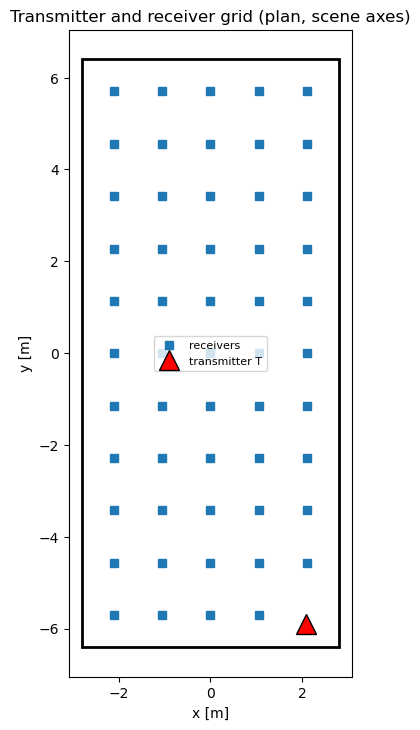

In [24]:
try:
    import sklearn
except ImportError:
    os.system("pip install scikit-learn"); import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import confusion_matrix, roc_auc_score

BEH_FREQ = 2.4e9                  # one frequency keeps the run time reasonable; 3.55e9 needs different body values (see BODY)
BEH_HEIGHT_M = 0.4                # height of T and of every receiver (the same low height as the primary set-up above, so a flame is on the links from its first stage)
BEH_GRID = (5, 11)                # receivers across the room (x) and along it (y)
BEH_MIN_DIST_TX = 0.8             # no receiver closer than this to T
N_PER_CLASS = 8 if QUICK_MODE else 30        # scenarios of each kind
N_FRAMES = 6 if QUICK_MODE else 8            # frames per scenario
FRAME_DT_S = 30                   # seconds between frames
INCLUDE_PEOPLE = False
MEAS_NOISE_DB = 0.5               # receiver noise added to every power value (assumption)
MEAS_NOISE_NS = 0.3               # and to the delay spread
SHADOW_DB = 6.0                   # a link is "affected" when its direct path falls by at least this much
FRAME_PATH_KW = dict(max_depth=3, los=True, specular_reflection=True, diffuse_reflection=False,
                     refraction=True, diffraction=False, samples_per_src=20_000, seed=SEED)   # lighter than PATH_KW: thousands of frames
# human body: muscle tissue at 2.45 GHz, relative permittivity about 53 and conductivity about 1.7 S/m (Gabriel et al. tissue data, from memory: check before citing)
BODY = dict(relative_permittivity=52.7, conductivity=1.74, scattering_coefficient=0.0)
PERSON_RADIUS_M, PERSON_HEIGHT_M = 0.22, 1.7
CACHE_FILE = f"{RESULTS_DIR}/behaviour_frames.npz"
USE_CACHE = True
CLASS_NAMES = ["empty", "people", "fire", "fire + people"] if INCLUDE_PEOPLE else ["empty", "fire"]
KIND = {"empty": "empty", "people": "people", "fire": "fire", "fire + people": "fire_people"}

MAT_BODY = RadioMaterial("body", thickness=PERSON_RADIUS_M, **BODY, color=(0.9, 0.7, 0.6))
T_BEH = np.array([T_MARK[0], T_MARK[1], FLOOR_Z + BEH_HEIGHT_M])
_gx = np.linspace(X0 + 0.7, X1 - 0.7, BEH_GRID[0]); _gy = np.linspace(Y0 + 0.7, Y1 - 0.7, BEH_GRID[1])
RX_LIST, RX_CELL = [], []
for iy, y in enumerate(_gy):
    for ix, x in enumerate(_gx):
        if np.hypot(x - T_BEH[0], y - T_BEH[1]) > BEH_MIN_DIST_TX: RX_LIST.append((x, y, FLOOR_Z + BEH_HEIGHT_M)); RX_CELL.append((iy, ix))
RX = np.array(RX_LIST); RX_CELL = np.array(RX_CELL); N_RX = len(RX)
D_DIRECT_NS = np.linalg.norm(RX - T_BEH, axis=1)/0.299792458          # straight-line delay to every receiver
print(f"T at {np.round(T_BEH, 2)}, {N_RX} receivers on a {BEH_GRID[0]} x {BEH_GRID[1]} grid, {len(CLASS_NAMES)} scenario kinds, {N_PER_CLASS} each, {N_FRAMES} frames")

def to_grid(v):
    g = np.full(BEH_GRID[::-1], np.nan); g[RX_CELL[:, 0], RX_CELL[:, 1]] = v; return g

fig, ax = plt.subplots(figsize=(4.2, 8.4))
ax.add_patch(Rectangle((X0, Y0), X1 - X0, Y1 - Y0, fill=False, lw=2)); ax.plot(RX[:, 0], RX[:, 1], "s", color="tab:blue", label="receivers")
ax.plot(T_BEH[0], T_BEH[1], "^", color="red", ms=14, mec="k", label="transmitter T"); ax.set_aspect("equal"); ax.legend(loc="center", fontsize=8)
ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]"); ax.set_title("Transmitter and receiver grid (plan, scene axes)"); plt.show()

## 14. Scenarios and frames

`make_scenario` draws a random scenario; `state_at` says what is in the room in each frame; `measure_frame` ray-traces the room and returns, for every receiver, the **direct-path power, early-arrival power, total power and delay spread**. The empty room is measured once as the reference. Frames then get receiver noise added (`MEAS_NOISE_DB`).

- **Fire:** ignites in frame `k0` (0 to 2), then grows from the small to the large size over 3 to 6 frames, with random flicker, at a random place. Smoke grows with it.
- **People (1 to 3):** each is either *standing* (almost still) or *walking* (moves 1 to 4 m between frames and bounces off the walls).
- People are kept at least 0.9 m from the fire.

In [25]:
rng_all = np.random.default_rng(SEED)
BEH_DIR = os.path.join(RESULTS_DIR, "behaviour_cache"); os.makedirs(BEH_DIR, exist_ok=True)

def free_xy(rs, avoid=(), min_d=0.9, margin=0.7):
    for _ in range(200):
        p = np.array([rs.uniform(X0 + margin, X1 - margin), rs.uniform(Y0 + margin, Y1 - margin)])
        if np.hypot(*(p - T_BEH[:2])) > 1.2 and all(np.hypot(*(p - a)) > min_d for a in avoid): return p
    return p

def make_scenario(kind, rs):
    sc = dict(kind=kind, fire=None, people=[])
    if "fire" in kind:
        s0, s1 = STAGES["small"], STAGES["large"]
        sc["fire"] = dict(xy=free_xy(rs, margin=0.9), k0=int(rs.integers(0, 3)), grow=int(rs.integers(3, 7)), fr=(s0["fire"], s1["fire"]), sm=(s0["smoke"], s1["smoke"]),
                          flick=rs.normal(1.0, 0.08, 64).clip(0.8, 1.2))
    if "people" in kind:
        for _ in range(int(rs.integers(1, 4 if kind == "people" else 3))):
            sc["people"].append(dict(mode="static" if rs.random() < 0.4 else "walk", xy=free_xy(rs, avoid=[sc["fire"]["xy"]] if sc["fire"] else []), seed=int(rs.integers(1 << 30))))
    return sc

def state_at(sc, k):
    """Fire size and people positions in frame k."""
    fire = None
    if sc["fire"] is not None and k >= sc["fire"]["k0"]:
        f = sc["fire"]; s = min(1.0, (k - f["k0"] + 1)/f["grow"])**0.8; fl = f["flick"][k]
        (r0, h0), (r1, h1) = f["fr"]; (sr0, sh0), (sr1, sh1) = f["sm"]
        fire = dict(xy=f["xy"], r=(r0 + (r1 - r0)*s)*fl, h=(h0 + (h1 - h0)*s)*fl, sr=(sr0 + (sr1 - sr0)*s)*fl, sh=(sh0 + (sh1 - sh0)*s)*fl, size=s)
    people = []
    for p in sc["people"]:
        rs = np.random.default_rng(p["seed"]); xy = p["xy"].copy()
        for _ in range(k):                                       # replay the walk up to frame k
            if p["mode"] == "walk":
                ang = rs.uniform(0, 2*np.pi); step = rs.uniform(1.0, 4.0); xy = xy + step*np.array([np.cos(ang), np.sin(ang)])
                xy[0] = np.clip(xy[0], X0 + 0.5, X1 - 0.5); xy[1] = np.clip(xy[1], Y0 + 0.5, Y1 - 0.5)
        if p["mode"] == "static": xy = xy + np.random.default_rng(p["seed"] + k).normal(0, 0.08, 2)
        if fire is not None and np.hypot(*(xy - fire["xy"])) < 0.9: xy = fire["xy"] + 0.9*(xy - fire["xy"])/max(np.hypot(*(xy - fire["xy"])), 1e-6)
        people.append(xy)
    return fire, people

_dyn = []
def set_dynamic(fire, people):
    """Replace the fire, smoke and people in the scene."""
    global _dyn
    add = []
    if fire is not None:
        fx, fy = fire["xy"]; r, h = fire["r"], fire["h"]
        V, F = ellipsoid((r, r, h/2), (fx, fy, FLOOR_Z + h/2), n_lat=8, n_lon=14, taper=(1.0, -0.6)); write_ply(f"{BEH_DIR}/fire.ply", ["x", "y", "z"], np.array(V), F)
        add.append(SceneObject(mi_mesh=load_mesh(f"{BEH_DIR}/fire.ply"), name="beh_fire", radio_material=MAT_FIRE))
        z0 = 0.8*h; sh = min(fire["sh"], (CEIL_Z - FLOOR_Z) - 0.05 - z0)
        V, F = ellipsoid((fire["sr"], fire["sr"], sh/2), (fx, fy, FLOOR_Z + z0 + sh/2), n_lat=8, n_lon=14, taper=(0.5, 0.5)); write_ply(f"{BEH_DIR}/smoke.ply", ["x", "y", "z"], np.array(V), F)
        add.append(SceneObject(mi_mesh=load_mesh(f"{BEH_DIR}/smoke.ply"), name="beh_smoke", radio_material=MAT_SMOKE))
    for i, xy in enumerate(people):
        V, F = ellipsoid((PERSON_RADIUS_M, PERSON_RADIUS_M, PERSON_HEIGHT_M/2), (xy[0], xy[1], FLOOR_Z + PERSON_HEIGHT_M/2), n_lat=8, n_lon=12); write_ply(f"{BEH_DIR}/p{i}.ply", ["x", "y", "z"], np.array(V), F)
        add.append(SceneObject(mi_mesh=load_mesh(f"{BEH_DIR}/p{i}.ply"), name=f"beh_p{i}", radio_material=MAT_BODY))
    scene.edit(add=add or None, remove=_dyn or None); _dyn = [o.name for o in add]

def measure_frame(freq):
    """Returns an (N_RX, 4) array: direct power, early power, total power (dBm) and RMS delay spread (ns) for every receiver."""
    scene.frequency = freq; paths = PathSolver()(scene, **FRAME_PATH_KW)
    a, tau = paths.cir(normalize_delays=False, out_type="numpy"); out = np.zeros((N_RX, 4)); out[:, :3] = DBM_FLOOR
    for i in range(N_RX):
        aa = np.abs(a[i, 0, 0, 0, :, 0])**2; tt = (tau[i, 0, :] if tau.ndim == 3 else tau[i, 0, 0, 0])*1e9
        ok = (tt >= 0) & (aa > 0)
        if not ok.any(): continue
        g, t = aa[ok], tt[ok]; p = TX_POWER_DBM + 10*np.log10(g); above = p > NOISE_FLOOR_DBM
        if not above.any(): continue
        out[i, 2] = TX_POWER_DBM + 10*np.log10(g[above].sum()); d = D_DIRECT_NS[i]
        near = above & (np.abs(t - d) < 1.5); early = above & (t >= d - 1.5) & (t <= d + EARLY_WINDOW_NS)
        if near.any(): out[i, 0] = p[near].max()
        if early.any(): out[i, 1] = TX_POWER_DBM + 10*np.log10(g[early].sum())
        vis = above & (p > p.max() - TAP_DYNAMIC_RANGE_DB); gv, tv = g[vis], t[vis]; tm = (gv*tv).sum()/gv.sum(); out[i, 3] = np.sqrt((gv*(tv - tm)**2).sum()/gv.sum())
    return out

# transmitter and receiver grid
set_nodes([T_BEH], [r for r in RX])

# reference: the empty room (first clear anything the earlier sections left in the scene)
try: set_hazards("baseline", "small", pos)
except Exception: pass
set_nodes([T_BEH], [r for r in RX])
set_dynamic(None, []); BASE = measure_frame(BEH_FREQ)
print("empty-room reference: direct power %.1f to %.1f dBm, total power %.1f to %.1f dBm" % (BASE[:, 0].min(), BASE[:, 0].max(), BASE[:, 2].min(), BASE[:, 2].max()))

# build the data set (cached: delete results/behaviour_frames.npz to regenerate)
sig = np.array([N_PER_CLASS, N_FRAMES, SEED, len(CLASS_NAMES), N_RX, int(BEH_FREQ/1e6)])
SCEN, LABEL, K0, FRAMES = [], [], [], None
loaded = False
if USE_CACHE and os.path.exists(CACHE_FILE):
    z = np.load(CACHE_FILE, allow_pickle=True)
    if np.array_equal(z["sig"], sig): FRAMES, LABEL, K0, SCEN = z["frames"], z["label"], z["k0"], list(z["scen"]); loaded = True; print("loaded the cached data set:", FRAMES.shape)
if not loaded:
    order = [(ci, j) for j in range(N_PER_CLASS) for ci in range(len(CLASS_NAMES))]       # interleave classes so an interrupted run is still balanced
    FRAMES = np.zeros((len(order), N_FRAMES, N_RX, 4)); LABEL = np.zeros(len(order), int); K0 = np.full(len(order), -1)
    t_start = time.time()
    for n, (ci, j) in enumerate(order):
        rs = np.random.default_rng(SEED + 7919*(n + 1)); sc = make_scenario(KIND[CLASS_NAMES[ci]], rs); SCEN.append(sc); LABEL[n] = ci
        K0[n] = sc["fire"]["k0"] if sc["fire"] else -1
        for k in range(N_FRAMES):
            fire, people = state_at(sc, k); set_dynamic(fire, people); m = measure_frame(BEH_FREQ)
            m[:, :3] = np.maximum(m[:, :3] + rs.normal(0, MEAS_NOISE_DB, (N_RX, 3)), DBM_FLOOR); m[:, 3] = np.maximum(m[:, 3] + rs.normal(0, MEAS_NOISE_NS, N_RX), 0)
            FRAMES[n, k] = m
        if (n + 1) % 10 == 0 or n + 1 == len(order):
            done = (n + 1)/len(order); print(f"{n + 1}/{len(order)} scenarios, {time.time() - t_start:.0f}s elapsed, about {(time.time() - t_start)*(1 - done)/done:.0f}s left")
    set_dynamic(None, [])
    np.savez_compressed(CACHE_FILE, sig=sig, frames=FRAMES, label=LABEL, k0=K0, scen=np.array(SCEN, dtype=object))

# changes relative to the empty room, in the form the features use
DROP_DIRECT = np.maximum(BASE[:, 0], DBM_FLOOR) - FRAMES[..., 0]; DROP_EARLY = np.maximum(BASE[:, 1], DBM_FLOOR) - FRAMES[..., 1]
DROP_TOTAL = np.maximum(BASE[:, 2], DBM_FLOOR) - FRAMES[..., 2]; D_DS = FRAMES[..., 3] - BASE[:, 3]
IS_FIRE = np.isin(np.array(CLASS_NAMES)[LABEL], ["fire", "fire + people"])
print("data set:", len(LABEL), "scenarios;", {c: int((LABEL == i).sum()) for i, c in enumerate(CLASS_NAMES)})

empty-room reference: direct power -57.5 to -20.4 dBm, total power -53.6 to -19.6 dBm
10/60 scenarios, 11s elapsed, about 57s left
20/60 scenarios, 23s elapsed, about 46s left
30/60 scenarios, 36s elapsed, about 36s left
40/60 scenarios, 49s elapsed, about 24s left
50/60 scenarios, 61s elapsed, about 12s left
60/60 scenarios, 73s elapsed, about 0s left
data set: 60 scenarios; {'empty': 30, 'fire': 30}


### What the data looks like
Each small map is the receiver grid, with T at the bottom right; colour is the fall in **direct-path power** relative to the empty room. One example per kind, frame by frame. A person leaves a small shadow that jumps around or stays put and never grows; a fire leaves a shadow that appears at one place and keeps getting wider.

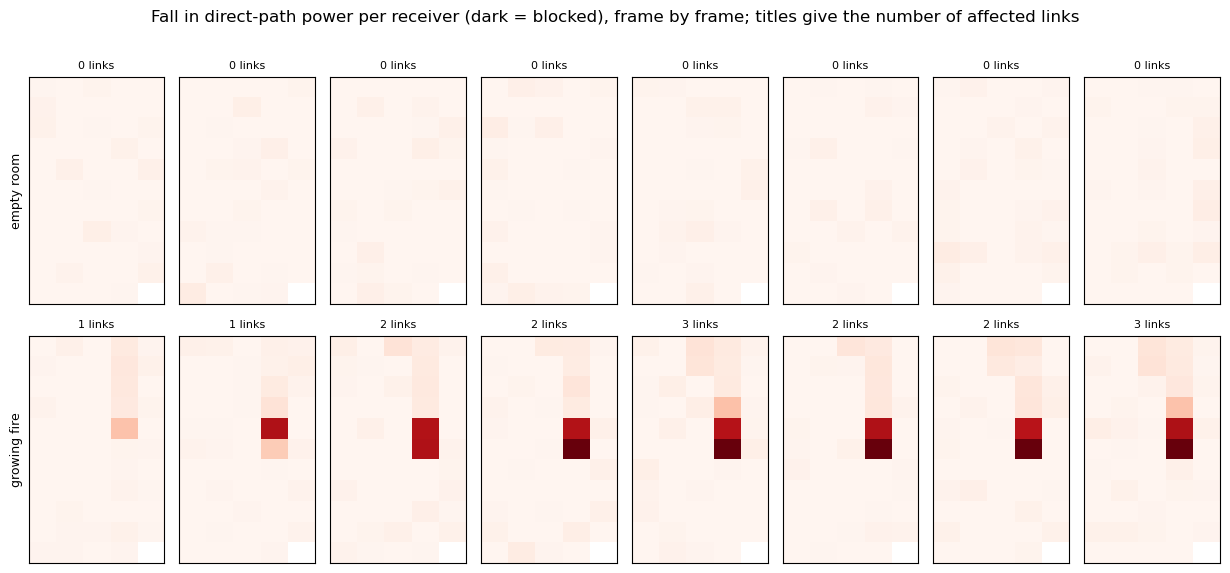

In [26]:
def example(kind_name, want=None):
    cands = [n for n in range(len(LABEL)) if CLASS_NAMES[LABEL[n]] == kind_name and (want is None or want(SCEN[n]))]
    return cands[0] if cands else None
rows = [("empty", None, "empty room"), ("people", lambda s: all(p["mode"] == "walk" for p in s["people"]), "walking people"),
        ("people", lambda s: all(p["mode"] == "static" for p in s["people"]), "standing people"), ("fire", None, "growing fire"),
        ("fire + people", None, "fire + people")]
rows = [(k, w, t) for k, w, t in rows if k in CLASS_NAMES]
fig, axes = plt.subplots(len(rows), N_FRAMES, figsize=(1.55*N_FRAMES, 2.9*len(rows)), squeeze=False)
for r_, (kname, want, title) in enumerate(rows):
    n = example(kname, want)
    for k in range(N_FRAMES):
        ax = axes[r_, k]
        if n is None: ax.axis("off"); continue
        d = DROP_DIRECT[n, k]; ax.imshow(to_grid(np.clip(d, 0, 30)), cmap="Reds", vmin=0, vmax=30, origin="lower", aspect="auto")
        ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{int((d >= SHADOW_DB).sum())} links", fontsize=8)
        if k == 0: ax.set_ylabel(title, fontsize=9)
fig.suptitle("Fall in direct-path power per receiver (dark = blocked), frame by frame; titles give the number of affected links"); plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

## 15. Behaviour features

For the first `k` frames of a scenario, the features describe how the **pattern of affected links** behaves. A link is *affected* when its direct-path power drops by at least `SHADOW_DB`.

| Feature | Idea |
|---|---|
| `frac_frames_affected`, `mean_n_affected`, `max_n_affected` | persistence and how many links are affected |
| `trend_n_affected`, `last_minus_first_n`, `frac_increasing_steps` | does the shadow **grow** (fire) or not |
| `variability_n`, `mean_abs_change_n` | does the number of affected links jump around (people) |
| `mean_iou_consecutive` | overlap between consecutive frames: high = same place, low = it moved |
| `centroid_step_m` | how far the shadow's centre moves between frames |
| `frac_recovered` | after the first blocked frame, how often the room is clear again (people leave, fire stays) |
| `core_size`, `core_share` | links affected in at least 70% of the frames after the first: a persistent object |
| `mean_drop_affected_db`, `early_drop_mean_db`, `total_drop_mean_db`, `ds_change_mean_ns`, `halo_links` | how deep the loss is, and effects outside the direct shadow |

In [27]:
def window_features(n_idx, k):
    d, e, t, s = DROP_DIRECT[n_idx, :k], DROP_EARLY[n_idx, :k], DROP_TOTAL[n_idx, :k], D_DS[n_idx, :k]
    S = d >= SHADOW_DB; n = S.sum(1).astype(float); tt = np.arange(k); f = {}
    f["frac_frames_affected"] = float((n > 0).mean()); f["mean_n_affected"] = float(n.mean()); f["max_n_affected"] = float(n.max())
    f["trend_n_affected"] = float(np.polyfit(tt, n, 1)[0]) if k >= 2 else 0.0; f["last_minus_first_n"] = float(n[-1] - n[0])
    inc = np.diff(n); f["frac_increasing_steps"] = float((inc > 0).mean()) if len(inc) else 0.0
    f["variability_n"] = float(n.std()); f["mean_abs_change_n"] = float(np.abs(inc).mean()) if len(inc) else 0.0
    ious = [(a_ & b_).sum()/(a_ | b_).sum() for a_, b_ in zip(S[:-1], S[1:]) if (a_ | b_).sum() > 0]; f["mean_iou_consecutive"] = float(np.mean(ious)) if ious else 0.0
    cents = [RX[m, :2].mean(0) if m.any() else None for m in S]
    steps = [np.linalg.norm(c2 - c1) for c1, c2 in zip(cents[:-1], cents[1:]) if c1 is not None and c2 is not None]; f["centroid_step_m"] = float(np.mean(steps)) if steps else 0.0
    first = int(np.argmax(n > 0)) if (n > 0).any() else None
    f["frac_recovered"] = float((n[first:] == 0).mean()) if first is not None else 0.0
    if first is not None:
        core = S[first:].mean(0) >= 0.7; f["core_size"] = float(core.sum()); f["core_share"] = float(core.sum()/max(n[first:].mean(), 1.0))
    else: f["core_size"] = 0.0; f["core_share"] = 0.0
    f["mean_drop_affected_db"] = float(d[S].mean()) if S.any() else 0.0
    f["early_drop_mean_db"] = float(e.mean()); f["total_drop_mean_db"] = float(t.mean()); f["ds_change_mean_ns"] = float(np.abs(s).mean())
    f["halo_links"] = float(((e >= 3.0) & ~S).sum(1).mean())
    return f

FEATURE_NAMES = list(window_features(0, N_FRAMES))
def feature_matrix(k): return np.array([[window_features(i, k)[nm] for nm in FEATURE_NAMES] for i in range(len(LABEL))])
XK = {k: feature_matrix(k) for k in range(2, N_FRAMES + 1)}
print(len(FEATURE_NAMES), "features; matrix for the full window:", XK[N_FRAMES].shape)

18 features; matrix for the full window: (60, 18)


## 16. Classifier and the threshold rule it is compared with

- **Targets:** the scenario kind (4 classes) and *fire present* (yes/no).
- **Models:** a standardised **logistic regression** and a **decision tree of depth 3**. Both are easy to inspect.
- **Evaluation:** 5-fold cross-validation **by scenario** (every scenario is predicted by a model that never saw it). The same is repeated with only the first `k` frames to see how early the classifier recognises a fire.
- **Threshold rule from sections 1 to 11, applied to this data:** alert if any receiver's direct path falls by at least `SHADOW_DB` in any frame. A second rule uses total power with a threshold of 1.5 times the largest fall seen in the empty-room scenarios (calibrated on the same data, so slightly optimistic).

In [28]:
def make_model(kind):
    if kind == "logistic": return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000, class_weight="balanced"))
    return DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=SEED, min_samples_leaf=3)
MODELS = ["logistic", "tree"]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
y_fire = IS_FIRE.astype(int)

PRED4, PROB_FIRE = {}, {}
for m in MODELS:
    PRED4[m] = {k: cross_val_predict(make_model(m), XK[k], LABEL, cv=skf) for k in XK}
    PROB_FIRE[m] = {k: cross_val_predict(make_model(m), XK[k], y_fire, cv=skf, method="predict_proba")[:, 1] for k in XK}

def naive_rules(k):
    S = (DROP_DIRECT[:, :k] >= SHADOW_DB).any(axis=(1, 2))
    thr_total = 1.5*max(DROP_TOTAL[LABEL == 0][:, :k].max(), 0.5)
    T_ = (DROP_TOTAL[:, :k] >= thr_total).any(axis=(1, 2)); return S, T_, thr_total
K_FULL = N_FRAMES
rule_direct, rule_total, THR_TOTAL = naive_rules(K_FULL)
print(f"total-power rule threshold: {THR_TOTAL:.2f} dB (1.5 x the largest fall in the empty-room scenarios)")

def rates(pred_fire):
    out = {}
    for ci, c in enumerate(CLASS_NAMES): out[c] = float(pred_fire[LABEL == ci].mean())
    return out
RATE = {"direct-path threshold rule": rates(rule_direct), "total-power threshold rule": rates(rule_total)}
for m in MODELS: RATE[f"{m} classifier"] = rates(PROB_FIRE[m][K_FULL] >= 0.5)
tab = pd.DataFrame({k: {f"{c}: flagged as fire": v[c] for c in CLASS_NAMES} for k, v in RATE.items()}).T
tab.to_csv(f"{RESULTS_DIR}/behaviour_alert_rates.csv"); display((tab*100).round(1).rename_axis("% of scenarios flagged as fire"))

total-power rule threshold: 2.82 dB (1.5 x the largest fall in the empty-room scenarios)


,empty: flagged as fire,fire: flagged as fire
% of scenarios flagged as fire,,
direct-path threshold rule,0.0,100.0
total-power threshold rule,0.0,100.0
logistic classifier,0.0,100.0
tree classifier,0.0,100.0


### Confusion matrices (full window)

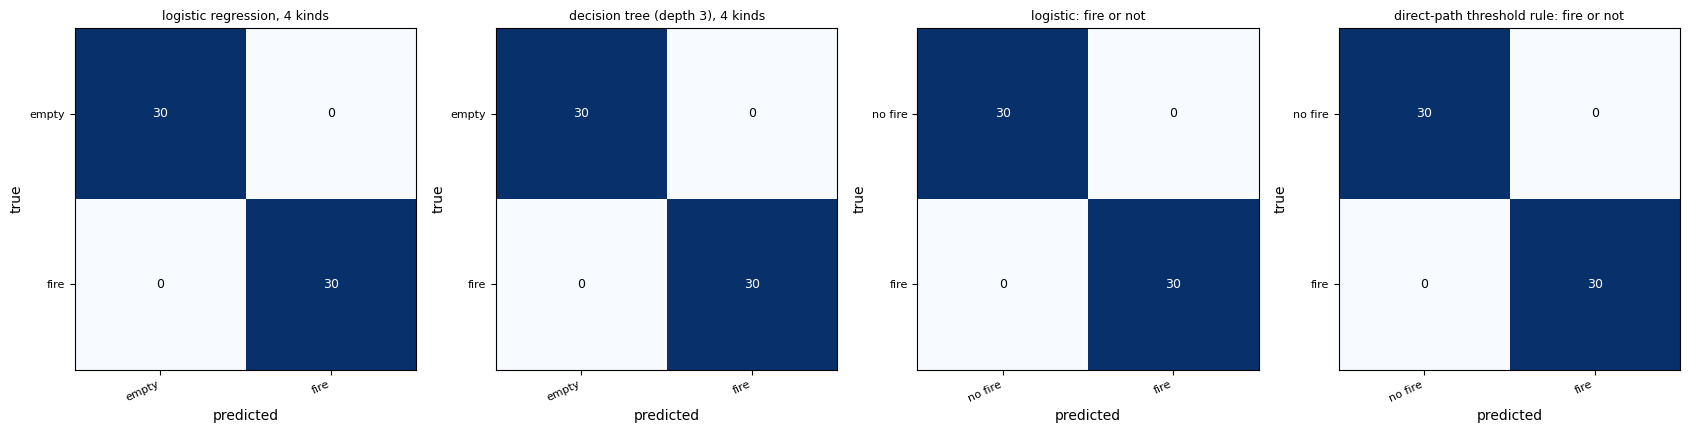

In [29]:
def show_cm(ax, y, p, labels, title):
    cm = confusion_matrix(y, p, labels=range(len(labels))); cmn = cm/np.maximum(cm.sum(1, keepdims=True), 1)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(labels)):
        for j in range(len(labels)): ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", color="white" if cmn[i, j] > 0.5 else "black", fontsize=9)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=25, ha="right", fontsize=8); ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=9)

fig, axes = plt.subplots(1, 3 + 1, figsize=(17, 4.4))
show_cm(axes[0], LABEL, PRED4["logistic"][K_FULL], CLASS_NAMES, "logistic regression, 4 kinds")
show_cm(axes[1], LABEL, PRED4["tree"][K_FULL], CLASS_NAMES, "decision tree (depth 3), 4 kinds")
show_cm(axes[2], y_fire, (PROB_FIRE["logistic"][K_FULL] >= 0.5).astype(int), ["no fire", "fire"], "logistic: fire or not")
show_cm(axes[3], y_fire, rule_direct.astype(int), ["no fire", "fire"], "direct-path threshold rule: fire or not")
plt.tight_layout(); plt.show()

### False alarms on people, and how early the fire is recognised
**Left:** share of fire scenarios detected, and share of empty / people-only scenarios falsely flagged, against the number of frames observed. **Right:** the delay between the fire appearing and the classifier first flagging it, for fire scenarios (frames after ignition; one frame is `FRAME_DT_S` seconds).

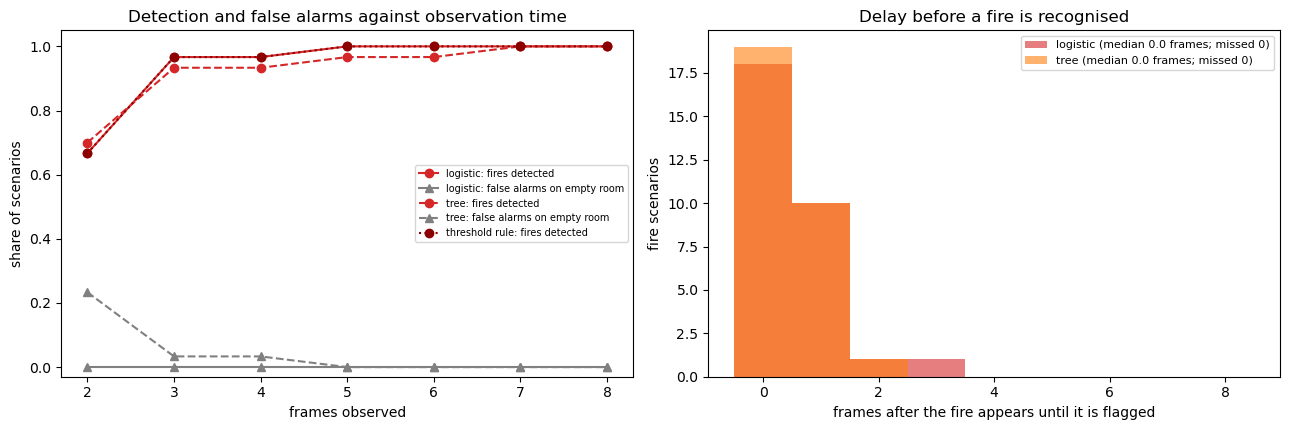

In [30]:
ks = sorted(XK)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
styles = {"logistic": "-", "tree": "--"}
for m in MODELS:
    pf = {k: PROB_FIRE[m][k] >= 0.5 for k in ks}
    axes[0].plot(ks, [pf[k][IS_FIRE].mean() for k in ks], styles[m], marker="o", color="tab:red", label=f"{m}: fires detected")
    if "people" in CLASS_NAMES: axes[0].plot(ks, [pf[k][LABEL == CLASS_NAMES.index("people")].mean() for k in ks], styles[m], marker="s", color="tab:blue", label=f"{m}: false alarms on people")
    axes[0].plot(ks, [pf[k][LABEL == 0].mean() for k in ks], styles[m], marker="^", color="gray", label=f"{m}: false alarms on empty room")
rd = [naive_rules(k)[0] for k in ks]
axes[0].plot(ks, [r[IS_FIRE].mean() for r in rd], ":", marker="o", color="darkred", label="threshold rule: fires detected")
if "people" in CLASS_NAMES: axes[0].plot(ks, [r[LABEL == CLASS_NAMES.index("people")].mean() for r in rd], ":", marker="s", color="navy", label="threshold rule: false alarms on people")
axes[0].set_xlabel("frames observed"); axes[0].set_ylabel("share of scenarios"); axes[0].set_ylim(-0.03, 1.05); axes[0].legend(fontsize=7, loc="center right"); axes[0].set_title("Detection and false alarms against observation time")

DELAY = {}
for m in MODELS:
    d_frames = []
    for i in np.where(IS_FIRE)[0]:
        det = [k for k in ks if PROB_FIRE[m][k][i] >= 0.5 and (k - 1) >= K0[i]]
        d_frames.append((min(det) - 1) - K0[i] if det else np.nan)
    DELAY[m] = np.array(d_frames)
bins = np.arange(-0.5, N_FRAMES + 1.5, 1)
for m, col in zip(MODELS, ("tab:red", "tab:orange")): axes[1].hist(DELAY[m][~np.isnan(DELAY[m])], bins=bins, alpha=0.6, color=col, label=f"{m} (median {np.nanmedian(DELAY[m]):.1f} frames; missed {int(np.isnan(DELAY[m]).sum())})")
axes[1].set_xlabel("frames after the fire appears until it is flagged"); axes[1].set_ylabel("fire scenarios"); axes[1].legend(fontsize=8); axes[1].set_title("Delay before a fire is recognised")
plt.tight_layout(); plt.show()

### What the classifier looks at
Left: the largest coefficients of the logistic regression (standardised features; positive = pushes toward "fire"). Right: how the most informative features differ between scenario kinds (full window).

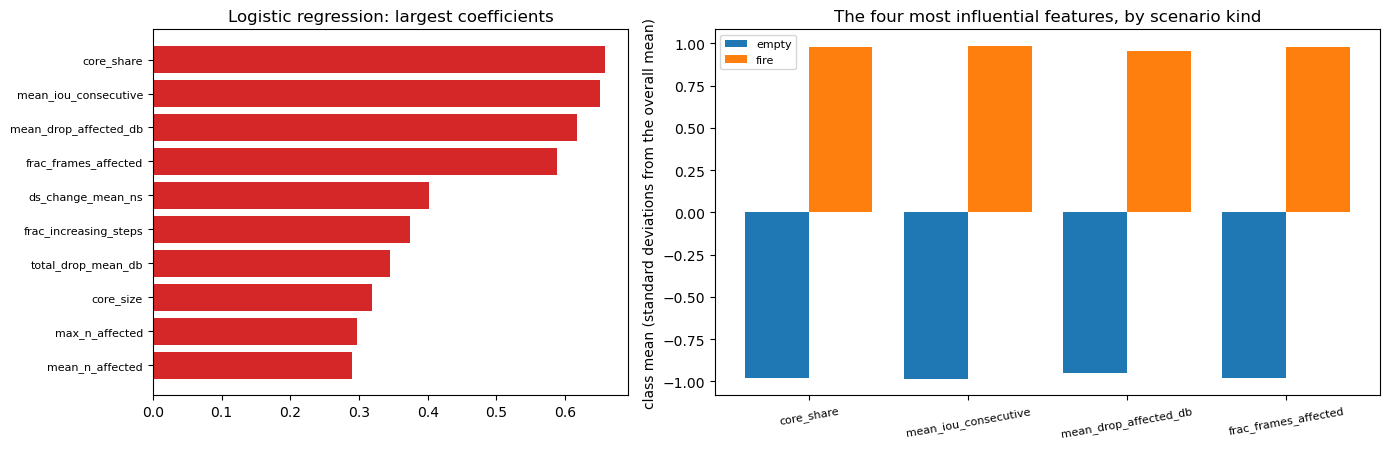

Decision tree (fire or not), depth 3:

|--- frac_frames_affected <= 0.25
|   |--- class: 0
|--- frac_frames_affected >  0.25
|   |--- class: 1



In [31]:
lr = make_model("logistic").fit(XK[K_FULL], y_fire); coef = lr.named_steps["logisticregression"].coef_[0]; top = np.argsort(-np.abs(coef))[:10]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw=dict(width_ratios=[1, 1.4]))
axes[0].barh([FEATURE_NAMES[i] for i in top][::-1], coef[top][::-1], color=["tab:red" if c > 0 else "tab:blue" for c in coef[top][::-1]]); axes[0].set_title("Logistic regression: largest coefficients"); axes[0].tick_params(axis="y", labelsize=8)
show = [FEATURE_NAMES[i] for i in top[:4]]; pos_ = 0; w = 0.8/len(CLASS_NAMES)
for ci, c in enumerate(CLASS_NAMES):
    vals = [(XK[K_FULL][LABEL == ci][:, FEATURE_NAMES.index(f_)].mean() - XK[K_FULL][:, FEATURE_NAMES.index(f_)].mean())/(XK[K_FULL][:, FEATURE_NAMES.index(f_)].std() + 1e-9) for f_ in show]
    axes[1].bar(np.arange(len(show)) + ci*w, vals, w, label=c)
axes[1].set_xticks(np.arange(len(show)) + 0.4 - w/2); axes[1].set_xticklabels(show, fontsize=8, rotation=10); axes[1].set_ylabel("class mean (standard deviations from the overall mean)"); axes[1].legend(fontsize=8); axes[1].set_title("The four most influential features, by scenario kind")
plt.tight_layout(); plt.show()
tree = make_model("tree").fit(XK[K_FULL], y_fire); print("Decision tree (fire or not), depth 3:\n"); print(export_text(tree, feature_names=FEATURE_NAMES))

## 17. Results (generated from the numbers above)

In [32]:
def pct(x): return f"{100*x:.0f}%"
R = RATE; lines = []
best = "logistic classifier"
for m in MODELS:
    r = R[f"{m} classifier"]; fire_detect = np.mean([r[c] for c in CLASS_NAMES if "fire" in c])
    lines.append(f"The {m} classifier flags {pct(fire_detect)} of fire scenarios, {pct(r['empty'])} of empty rooms" + (f" and {pct(r['people'])} of people-only scenarios" if "people" in r else "") + f" as fire (5-fold cross-validation, {K_FULL} frames = {K_FULL*FRAME_DT_S} s observed).")
r = R["direct-path threshold rule"]; fd = np.mean([r[c] for c in CLASS_NAMES if "fire" in c])
lines.append(f"The direct-path threshold rule from sections 1 to 11 flags {pct(fd)} of fire scenarios but also {pct(r['empty'])} of empty rooms" + (f" and {pct(r['people'])} of people-only scenarios." if "people" in r else "."))
for m in MODELS:
    dd = DELAY[m]; ok = ~np.isnan(dd)
    lines.append(f"{m}: a fire is recognised a median of {np.nanmedian(dd):.1f} frames ({np.nanmedian(dd)*FRAME_DT_S:.0f} s) after it appears; {int((~ok).sum())} of {len(dd)} fires were never flagged within {K_FULL} frames.")
if "people" in CLASS_NAMES:
    pi = CLASS_NAMES.index("people"); idx = np.where(LABEL == pi)[0]
    mode = np.array(["standing only" if {p["mode"] for p in SCEN[n]["people"]} == {"static"} else "walking only" if {p["mode"] for p in SCEN[n]["people"]} == {"walk"} else "mixed" for n in idx])
    br = pd.DataFrame({name: {m_: float(flag[idx][mode == m_].mean()) if (mode == m_).any() else np.nan for m_ in ("walking only", "mixed", "standing only")}
                       for name, flag in (("direct-path threshold rule", rule_direct), ("logistic classifier", PROB_FIRE["logistic"][K_FULL] >= 0.5), ("tree classifier", PROB_FIRE["tree"][K_FULL] >= 0.5))})
    br["scenarios"] = [int((mode == m_).sum()) for m_ in br.index]; br.to_csv(f"{RESULTS_DIR}/behaviour_people_breakdown.csv")
    print("\nFalse alarms on people-only scenarios, by how the people behave:"); display((br.assign(**{c: br[c]*100 for c in br.columns[:-1]})).round(0))
    lines.append("False alarms on people come from " + ", ".join(f"{m_} ({br.loc[m_, 'logistic classifier']*100:.0f}% flagged by the logistic classifier, {int(br.loc[m_, 'scenarios'])} scenarios)" for m_ in br.index if br.loc[m_, 'scenarios'] > 0) + ".")
print("\n".join(" - " + l for l in lines))
pd.DataFrame({"model": MODELS, "median_delay_frames": [np.nanmedian(DELAY[m]) for m in MODELS], "missed_fires": [int(np.isnan(DELAY[m]).sum()) for m in MODELS]}).to_csv(f"{RESULTS_DIR}/behaviour_delay.csv", index=False)
pd.DataFrame(XK[K_FULL], columns=FEATURE_NAMES).assign(kind=np.array(CLASS_NAMES)[LABEL], fire_k0=K0).to_csv(f"{RESULTS_DIR}/behaviour_features.csv", index=False)

 - The logistic classifier flags 100% of fire scenarios, 0% of empty rooms as fire (5-fold cross-validation, 8 frames = 240 s observed).
 - The tree classifier flags 100% of fire scenarios, 0% of empty rooms as fire (5-fold cross-validation, 8 frames = 240 s observed).
 - The direct-path threshold rule from sections 1 to 11 flags 100% of fire scenarios but also 0% of empty rooms.
 - logistic: a fire is recognised a median of 0.0 frames (0 s) after it appears; 0 of 30 fires were never flagged within 8 frames.
 - tree: a fire is recognised a median of 0.0 frames (0 s) after it appears; 0 of 30 fires were never flagged within 8 frames.


## 18. How to read this, and its limits

- **It is a simulator study.** The fire's growth, flicker and position, and the people's movement, are rules written in this notebook. The classifier learns those rules, so a high score shows that behaviour is separable *under these assumptions*, not that it works in a real room.
- **People are simple.** Cylinders of muscle tissue (permittivity about 53, conductivity about 1.7 S/m at 2.4 GHz; check these values before citing) moving randomly. Real people sit, carry things, open doors and cluster.
- **A person who stands still on the same links for the whole window** looks like a small static blocker. The classifier separates it from a fire mainly through **growth**: a fire's shadow widens, a person's does not. A fire that is already large when observation starts, or one that stops growing, is harder.
- **Direct-path and early-arrival power need a receiver that resolves about 10 ns** (roughly 100 MHz). The simulation assumes this. A 20 MHz Wi-Fi channel cannot separate the direct path from the reflections that follow it.
- **Fire and smoke values are assumptions** (fire conductivity 0.05 S/m from one measurement of a vegetation fire; smoke values assumed). The fire is a thin slab, not a volume.
- **Lighter ray tracing for speed** (`FRAME_PATH_KW`: three reflections, no diffuse scattering, 20 000 rays) so thousands of frames can be computed. Receiver noise is a fixed Gaussian, not a measured one.
- **The comparison with the threshold rule is not fully independent** (the total-power rule's threshold is calibrated on the same empty scenarios).
- **Small data set, single room, single frequency, one transmitter position.** Treat percentages as indicative; with 30 scenarios per kind, one scenario is about 3% of a class.
- **Not yet tested:** other room layouts (furniture), other fire positions relative to T, several fires, and doors opening.

**Outputs** are in `results/`: `behaviour_frames.npz` (all frames, so the analysis can be rerun without ray tracing), `behaviour_alert_rates.csv`, `behaviour_delay.csv`, `behaviour_features.csv`.